# Feature Importance Analyses for Mislocalized Variants

We select for the interpretable CellProfiler features that contribute most significantly in the XGBoost Classifier to help distinguish the mislocalized variants from their respective reference alleles.

In [1]:
import os
import polars as pl
import seaborn as sns
from adjustText import adjust_text
from sklearn.decomposition import PCA
import umap
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
from functools import reduce
import operator
from tqdm import tqdm

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

# controls = {
#     "TC": ["EGFP"],
#     "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
#     "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
#     # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
#     # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
#     # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
#     # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
# }
# ctrl_alleles = [k_v for k_v in controls.values()]
# ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
# # ctrl_alleles_flat

np.random.seed(42)
random.seed(42)

## 1. Load feature importance and classifier info

### 1.1 Feature importance for each variant

In [2]:
## classification results in SM pipeline
SM_CLASS_RES_DIR = CLASS_RESULTS_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells"
FEAT = "GFP"
MISLOCALIZED_LABEL = "Altered_95th_perc_both_batches_GFP"

In [3]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col(MISLOCALIZED_LABEL)==1
)
allele_list = list(imaging_summary_clinvar["gene_allele"]) + list(imaging_summary_clinvar["Gene"].unique())
hits_allele_list = list(imaging_summary_clinvar_hits["gene_allele"]) + list(imaging_summary_clinvar_hits["Gene"].unique())
bio_reps = list(imaging_summary_clinvar_hits["Metadata_Bio_Batch"].unique())

In [4]:
imaging_summary_clinvar_hits

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,…,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category
str,str,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,i64,f64,str,…,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str,f64,f64,str,str
"""SMARCB1""","""SMARCB1_Pro48Leu""",-4.744349,0.002097,-10.576204,0.000015,"""2025_03_Batch_15-16""",true,true,true,true,true,true,true,false,true,true,0.996378,0.992405,0.984188,0.988582,0.962704,0.936465,0.981221,0.977555,0.988163,0.994737,0.988943,0.995942,0.990821,0.996648,0.998018,"""SMARCB1""","""ENSG00000099956""",53965,204888.0,"""CCSBVarC005063""",…,2.3791805e7,"""22q11.23""","""criteria provided, single subm…",2.0,"""-""","""N""","""ClinGen:CA129018,OMIM:601607.0…",3.0,30202.0,2.3791805e7,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV001512543""","""-""","""-""","""143C>T ""","""Pro48Leu""","""NM_003073.5""",1.0,"""4_VUS""",92.49,0.433824,"""['162091']""","""autosomal dominant""","""Rare genetic developmental def…",5,"""SCHWANNOMATOSIS 1""",92.49,0.433824,"""10-90""",""">90"""
"""MVK""","""MVK_Leu265Pro""",-3.469454,0.032036,-6.561184,0.010338,"""2024_12_Batch_11-12""",true,true,true,true,false,true,true,false,true,false,0.9921,0.991156,0.972623,0.987362,0.933829,0.957179,0.987779,0.972903,0.991911,0.991815,0.910479,0.986946,0.972343,0.990401,0.992385,"""MVK""","""ENSG00000110921""",281,200099.0,"""CCSBVarC004842""",…,1.09591266e8,"""12q24.11""","""no classification provided""",1.0,"""-""","""N""","""ClinGen:CA149901,UniProtKB:Q03…",2.0,97626.0,1.09591266e8,"""T""","""C""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000115983""","""-""","""-""","""794T>C ""","""Leu265Pro""","""NM_000431.4""",null,"""5_Others""",98.29,0.02439,"""['260920']""","""autosomal recessive""","""Rare genetic systemic or rheum…",6,"""HYPER-IgD SYNDROME""",98.29,0.02439,"""<10""",""">90"""
"""KRT8""","""KRT8_Arg454Cys""",-1.583367,0.164427,-2.806288,0.026286,"""2024_01_Batch_7-8""",true,false,false,false,false,false,false,false,false,false,0.979169,0.909544,0.952069,0.930835,0.771028,0.943884,0.971474,0.984433,0.972406,0.993686,0.598172,0.890197,0.919704,0.846683,0.964652,"""KRT8""","""ENSG00000170421""",14966,218520.0,"""CCSBVarC004269""",…,5.289752e7,"""12q13.13""","""no classification provided""",1.0,"""-""","""N""",""

### 1.2 Select for the CP features with importance > 1e-3 for each variant

In [5]:
# feat_import_df_feat = pl.DataFrame()
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         # Read the data
#         feat_df = pl.scan_csv(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id)}/feat_importance.csv")
#         meta_cols = [c for c in feat_df.collect_schema().names() if c.startswith("Metadata_") or c.startswith("Group") or c == "Batch"]
#         feat_cols = [c for c in feat_df.collect_schema().names() if c not in meta_cols and FEAT in c]
#         feat_df_batch = feat_df.with_columns(
#             [pl.col(c).cast(pl.Float64, strict=False).alias(c) for c in feat_cols]
#         ).with_columns(
#             pl.lit(batch_id).alias("Metadata_Batch"),
#             pl.col("Group2").str.split('_').list.slice(-2).list.join("_").alias("Metadata_gene_allele")
#        ).filter(
#             (pl.col("Metadata_Feature_Type")==FEAT)&(~pl.col("Metadata_Control"))
#             &(pl.col("Group1").is_in(allele_list)|(pl.col("Metadata_gene_allele").is_in(batch_allele_list)))
#         ).select(meta_cols + feat_cols + ["Metadata_Batch", "Metadata_gene_allele"])
#         feat_import_df_feat = pl.concat([feat_import_df_feat, feat_df_batch.collect()], how="diagonal")

In [6]:
# key_alleles_df = imaging_summary_clinvar.to_pandas()
# feat_df = pl.DataFrame()
# importance_thres = 1e-3
# # top_num = 5

# for j, allele in tqdm(key_alleles_df.iterrows()):
#     batch_list = list(feat_import_df_feat.filter(
#         pl.col("Metadata_gene_allele")==allele["gene_allele"]
#     ).unique("Metadata_Batch")["Metadata_Batch"])
#     allele_df = pl.DataFrame()
#     for i, batch in enumerate(batch_list):
#         batch_df = feat_import_df_feat.filter(
#             (pl.col("Metadata_Batch")==batch)&(pl.col("Metadata_gene_allele")==allele["gene_allele"])
#         )
#         feat_cols = [col for col in batch_df.columns if "Metadata" not in col and "Group" not in col]
#         batch_df = batch_df.filter(
#             ~pl.all_horizontal(pl.col(feat_cols).is_null())
#         )
#         non_null_gfp = [col for col in feat_cols if not batch_df[col].is_null().any()]
#         batch_df_col = (
#             batch_df.select(non_null_gfp).mean()
#            .transpose(include_header=True)
#            .filter(pl.col("column_0") > importance_thres)
#            .sort("column_0", descending=True)
#            # .head(top_num)#["column"]
#            # .to_list()
#         )
#         if not allele_df.is_empty():
#             allele_df = allele_df.join(
#                 batch_df_col.with_columns(
#                     pl.col("column_0").alias(batch),
#                     pl.col("column").alias("index"),
#                 ).select("index", batch),
#                 on="index",
#                 how="full",
#                 coalesce=True
#             )
#         else:
#             allele_df = batch_df_col.with_columns(
#                 pl.col("column_0").alias(batch),
#                 pl.col("column").alias("index"),
#             ).select("index", batch)
            
#     allele_df = allele_df.with_columns(
#         pl.mean_horizontal(pl.col([col for col in allele_df.columns if "Batch" in col])).alias("feat_importance"),
#         pl.col("index").alias("cp_feature")
#     ).select(
#         pl.col(["cp_feature", "feat_importance"])
#     ).rename(
#         {"feat_importance": allele["gene_allele"]}
#     )
#     if not feat_df.is_empty():
#         feat_df = feat_df.join(
#             allele_df,
#             left_on="cp_feature",
#             right_on="cp_feature",
#             how="full",
#             coalesce=True
#         )
#     else:
#         feat_df = allele_df

915it [02:45,  5.54it/s]


In [8]:
# feat_df.write_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

### 1.3 Load CellProfiler features

#### Loading QC info per each imaging well

In [17]:
## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")
feat_df.shape

(267, 916)

In [10]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

#### Load the features from the valid cells only

In [12]:
# # Paths
# ref_var_cell_qc_prof_df = pl.DataFrame()
# target_gene_alleles = []
# meta_cols = [
#     "Metadata_CellID",
#     "Metadata_gene_allele",
#     "Metadata_Well",
#     "Metadata_Plate",
#     "Metadata_node_type"
# ]

# # Get meta features
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 PASS_QC_PROF_PQ.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         ).collect()
#         # feat_cols = [col for col in batch_alleles.columns if ("AGP".lower() in col.lower() or "DNA".lower() in col.lower() or "Mito".lower() in col.lower()) and ("GFP".lower() not in col.lower())]
#         batch_alleles = batch_alleles.join(
#             img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==FEAT).select(pl.col("plate", "well", "is_bg")),
#             left_on=["Metadata_Plate", "Metadata_Well"],
#             right_on=["plate", "well"]
#         ).filter(
#             ~pl.col("is_bg")
#         ).select(pl.col(meta_cols))
#         ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

#### Load all the features available

In [14]:
# # Paths
# ref_var_cell_all_prof_list = []
# for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 ALL_PROF_QC.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         )
#         ref_var_cell_all_prof_list.append(batch_alleles)

# all_feat_cols = reduce(set.intersection, map(set, [[col for col in ref_var_cell_all_prof.collect_schema() if (FEAT.lower() in col.lower()) and ("Brightfield".lower() not in col.lower())] for ref_var_cell_all_prof in ref_var_cell_all_prof_list]))
# select_cols = list(all_feat_cols) + ["Metadata_CellID"]
# ref_var_cell_all_prof_df = pl.concat([batch_alleles.select(select_cols).collect() for batch_alleles in ref_var_cell_all_prof_list])
# # This method of joining ensures that only cells past filters are included in the abundance analysis
# ref_var_cell_all_prof_df = ref_var_cell_qc_prof_df.join(ref_var_cell_all_prof_df, 
#                                                         on="Metadata_CellID", 
#                                                         how="left", coalesce=True)

### 1.4 Aggregate the feature to batch-allele level

In [19]:
# ref_var_cell_all_prof_df = ref_var_cell_all_prof_df.with_columns(
#     pl.col("Metadata_Plate")
#       # capture a “B” followed by any non-underscore chars up to the first “A”
#       .str.extract(r"(B[^_]*?A)", 1)
#       .alias("Metadata_Batch")
# ).with_columns(
#     pl.col("Metadata_Batch").replace(BIO_BATCH_MAP_DICT).alias("Metadata_Bio_Batch")
# )

# ref_var_allele_batch_all_prof_df = ref_var_cell_all_prof_df.group_by(
#     "Metadata_Plate", "Metadata_Well", "Metadata_gene_allele", "Metadata_Bio_Batch"
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).group_by(
#     "Metadata_gene_allele", "Metadata_Bio_Batch"
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).unique(subset=["Metadata_gene_allele","Metadata_Bio_Batch"])

# non_null_cols_batch = [c for c in feat_df["cp_feature"].to_list() if c in ref_var_allele_batch_all_prof_df.columns]
# var_allele_meta_cols = [col for col in ref_var_allele_batch_all_prof_df.columns if "Metadata" in col]
# ref_var_allele_batch_all_prof_df = ref_var_allele_batch_all_prof_df.select(
#     var_allele_meta_cols+non_null_cols_batch
# )
# ref_var_allele_batch_all_prof_df

Metadata_gene_allele,Metadata_Bio_Batch,Cells_Correlation_RWC_Mito_GFP,Nuclei_Correlation_K_GFP_AGP,Cytoplasm_Intensity_MaxIntensity_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_K_GFP_Mito,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_RWC_GFP_DNA,Nuclei_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_Correlation_RWC_DNA_GFP,Nuclei_Texture_SumAverage_GFP_20_00_256,Cytoplasm_Granularity_1_GFP,Nuclei_Correlation_RWC_GFP_AGP,Cells_Correlation_RWC_DNA_GFP,Nuclei_Correlation_RWC_AGP_GFP,Cells_RadialDistribution_FracAtD_GFP_7of10,Nuclei_Correlation_Overlap_AGP_GFP,Nuclei_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_DNA_GFP,Cells_Texture_DifferenceVariance_GFP_20_01_256,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_Texture_Correlation_GFP_20_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Cells_Texture_InverseDifferenceMoment_GFP_20_03_256,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cytoplasm_Granularity_4_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cells_Correlation_RWC_GFP_Mito,Cytoplasm_Granularity_2_GFP,Nuclei_RadialDistribution_FracAtD_GFP_5of10,Cells_Correlation_Manders_GFP_Mito,Cells_RadialDistribution_MeanFrac_GFP_7of10,Cells_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Correlation_RWC_GFP_AGP,…,Cytoplasm_Texture_Correlation_GFP_5_01_256,Cytoplasm_Texture_InfoMeas1_GFP_20_03_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_01_256,Cells_Texture_AngularSecondMoment_GFP_20_02_256,Cytoplasm_Correlation_Correlation_AGP_GFP,Cells_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_RadialDistribution_FracAtD_GFP_3of10,Nuclei_Texture_AngularSecondMoment_GFP_10_00_256,Cells_Correlation_RWC_GFP_AGP,Nuclei_Texture_SumAverage_GFP_20_01_256,Cytoplasm_RadialDistribution_MeanFrac_GFP_4of10,Cytoplasm_Texture_AngularSecondMoment_GFP_5_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_10_01_256,Nuclei_RadialDistribution_FracAtD_GFP_4of10,Cytoplasm_RadialDistribution_RadialCV_GFP_4of10,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Cytoplasm_Texture_InfoMeas2_GFP_10_03_256,Nuclei_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_InverseDifferenceMoment_GFP_10_01_256,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Texture_InfoMeas1_GFP_20_00_256,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Texture_InfoMeas1_GFP_10_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cells_Granularity_3_GFP,Cells_Texture_Entropy_GFP_5_00_256,Cells_Texture_InfoMeas2_GFP_5_02_256,Nuclei_Texture_Correlation_GFP_10_03_256,Cytoplasm_RadialDistribution_FracAtD_GFP_6of10,Nuclei_RadialDistribution_MeanFrac_GFP_7of10,Cytoplasm_Texture_Entropy_GFP_20_03_256,Nuclei_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_20_01_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_00_256
str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""THAP1_Val193Ile""","""B7A""",-0.471381,0.30363,-0.855684,-0.098502,1.281638,-1.503473,1.243952,2.200505,0.823849,0.744993,-0.068026,1.291592,-0.67536,1.270144,-0.572945,0.000919,-0.889777,-1.161589,-0.111733,2.982598,3.686163,-1.511673,4.215372,-0.995179,0.99559,0.015394,-0.460648,2.00149,-0.614915,-0.982061,1.422735,-0.569082,-0.075004,0.517468,0.162354,…,1.136268,1.0,1.569049,2.139963,-0.54894,0.986725,1.13695,1.022571,-0.038973,-0.065695,-0.18443,1.0,2.306587,1.212851,-0.860611,0.981051,-1.0,1.454203,1.0,0.017828,1.0,-1.0,0.995265,1.398547,1.0,0.991164,-0.1125,-0.981556,-1.494422,0.73372,0.042101,1.48114,-1.0,0.962871,3.046467,1.0,1.0
"""F9_Arg384Leu""","""B13A

In [20]:
# ref_var_allele_batch_all_prof_df.write_csv("../../3_outputs/all_batch_alleles_featselect_cp_features.csv")

### 1.5 Process the CP feature by INT and remove correlated features

In [21]:
ref_var_allele_batch_all_prof_df = pl.read_csv("../../3_outputs/all_batch_alleles_featselect_cp_features.csv")
ref_var_allele_batch_all_prof_df = ref_var_allele_batch_all_prof_df.filter(pl.col("Metadata_gene_allele").is_in(allele_list))

In [21]:
sns.displot(
    x=ref_var_allele_batch_all_prof_df.select(
        pl.col([c for c in ref_var_allele_batch_all_prof_df.columns if "Meta" not in c])
    ).mean().transpose(include_header=True).rename({"column_0": "CP_Feature_Mean"})["CP_Feature_Mean"],
    height=4, aspect=1.2
)

In [36]:
from utils import *
from pycytominer.feature_select import feature_select

## normalize the features
ref_var_allele_batch_proc_prof_df = inverse_normal_transform(ref_var_allele_batch_all_prof_df)

## remove corr features
ref_var_allele_batch_proc_prof_df = feature_select(ref_var_allele_batch_proc_prof_df.to_pandas(), operation="variance_threshold")
ref_var_allele_batch_proc_prof_df = feature_select(ref_var_allele_batch_proc_prof_df, operation="correlation_threshold")
# ref_var_allele_batch_proc_prof_df = remove_corr_feats(ref_var_allele_batch_proc_prof_df)

In [37]:
ref_var_allele_batch_proc_prof_df

,Metadata_gene_allele,Metadata_Bio_Batch,Cells_Correlation_RWC_Mito_GFP,Nuclei_Correlation_K_GFP_Mito,Nuclei_Correlation_RWC_GFP_DNA,Nuclei_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Nuclei_Correlation_RWC_GFP_AGP,Cells_Correlation_RWC_DNA_GFP,Nuclei_Correlation_RWC_AGP_GFP,...,Nuclei_Texture_SumAverage_GFP_20_02_256,Cytoplasm_Location_CenterMassIntensity_Y_GFP,Cells_Correlation_RWC_AGP_GFP,Nuclei_Granularity_1_GFP,Cells_Texture_InfoMeas1_GFP_5_00_256,Cytoplasm_Texture_InfoMeas2_GFP_10_03_256,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cells_Granularity_3_GFP,Cells_Texture_InfoMeas2_GFP_5_02_256,Nuclei_Texture_InverseDifferenceMoment_GFP_20_00_256
0,THAP1_Val193Ile,B7A,-0.591951,1.035393,2.683686,1.219076,1.584382,-1.337474,2.850218,-0.609440,...,-0.978818,-1.633199,-0.032251,0.578952,1.082284,-1.222922,-0.310968,-0.508411,-1.091069,1.322739
1,F9_Arg384Leu,B13A,-0.041992,-0.897565,-0.551825,-0.621203,-0.099333,0.403075,-0.698361,-0.449720,...,1.346457,-0.374204,-0.625636,-0.890307,0.403075,0.593401,2.683686,1.471107,0.934589,-1.349475
2,TPM1_Glu54Lys,B15A,0.522307,0.533497,0.179217,-2.230291,0.698361,0.881300,1.104405,1.994325,...,-0.437636,-0.476813,1.666414,0.142236,-0.230168,0.033469,0.082227,-0.936474,-0.100556,0.804906
3,ABCD1_Arg518Gln,B14A,-1.008724,1.985513,-0.571773,0.393853,0.395169,-0.682916,-0.457812,-0.849450,...,-1.401164,0.418964,-0.544755,2.012429,1.797035,-1.511809,0.914071,-1.043748,-1.976853,0.761905
4,BRAF_Leu485Phe,B14A,0.587607,-1.337474,-0.530694,0.100556,-0.863497,1.221638,-0.070024,0.455111,...,1.875823,-0.763533,0.323764,-1.619500,0.412331,1.102169,-0.397801,0.232668,1.968338,-1.633199
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2055,BRCA1_Met1Thr,B14A,-0.001825,1.904877,-0.043210,-0.560347,1.316924,0.786536,1.515635,1.370957,...,-1.401164,-0.613841,1.527249,1.828492,1.989900,-1.621762,-0.414982,-1.555181,-2.522558,2.553011
2056,NT5C3A_Phe31Leu,B16A,0.279193,1.171838,1.389887,0.870585,1.855028,-0.090777,1.912397,1.415930,...,-0.630082,-0.403075,1.985513,0.994657,1.606098,-1.222922,0.027382,-2.175246,-1.393091,1.879369
2057,MVK_Ile119Met,B8A,1.841598,-0.540525,-0.296950,-0.858210,-0.334040,0.732945,-0.026164,0.976855,...,0.875930,-0.222678,0.654008,-1.406052,-0.597760,1.361673,0.868809,0.432285,0.842489,-0.833844
2058,LITAF_Leu122Val,B16A,0.169334,0.868809,1.097712,0.707709,1.555181,0.594853,1.559272,1.855028,...,-0.630082,-0.245188,1.157453,0.892117,1.358605,-0.921487,-0.210221,-1.374078,-1.221638,1.239802


Computing UMAP embedding...


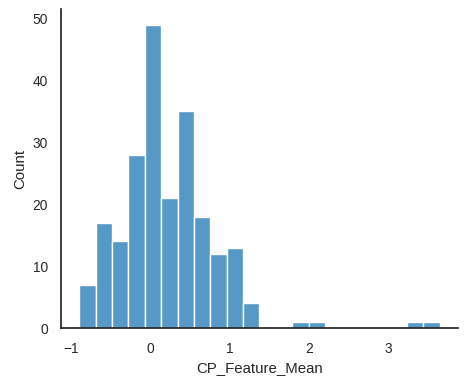

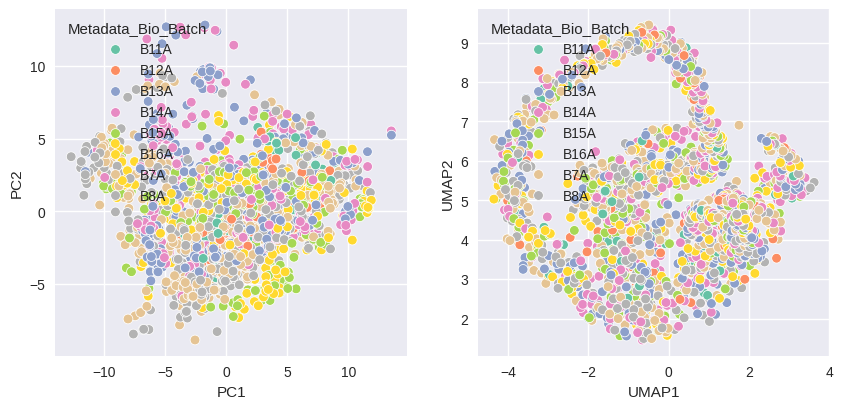

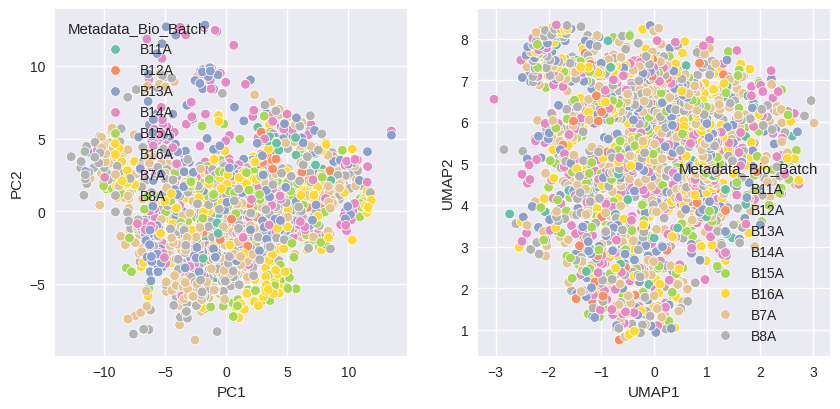

In [32]:
# UMAP - excellent for binary/sparse data
print("Computing UMAP embedding...")
umap_reducer = umap.UMAP(n_components=2, random_state=42, 
                       metric='jaccard', n_neighbors=15, min_dist=0.1)
X_umap = umap_reducer.fit_transform(ref_var_allele_batch_proc_prof_df.select(
    [c for c in ref_var_allele_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(ref_var_allele_batch_proc_prof_df.select(
    [c for c in ref_var_allele_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

umap_df = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_Bio_Batch"] = ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"]
umap_df["Metadata_gene_allele"] = ref_var_allele_batch_proc_prof_df["Metadata_gene_allele"]

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Metadata_Bio_Batch"] = ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"]
pca_df["Metadata_gene_allele"] = ref_var_allele_batch_proc_prof_df["Metadata_gene_allele"]

fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Metadata_Bio_Batch", palette="Set2", ax=axes[0],
                hue_order=sorted(ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"].unique()))
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Metadata_Bio_Batch", palette="Set2",  ax=axes[1],
               hue_order=sorted(ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"].unique()))
plt.show()

### 1.6 Loading gene location info

In [33]:
gene_loc_df = pl.read_csv("../../3_outputs/agg_gene_normalized_cp_profiles_subloc.csv")
# hits_gene_loc_df = gene_loc_df.filter(
#     pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["Gene"].unique())
# )

# fig, axes = plt.subplots(1,2,figsize=(15,5))
# sns.barplot(
#     data=hits_gene_loc_df.group_by("Main location").agg(pl.len()).sort("len", descending=True),
#     x="len",
#     y="Main location",
#     ax=axes[0]
# )
# sns.barplot(
#     data=hits_gene_loc_df.group_by("Final_Loc").agg(pl.len()).sort("len", descending=True),
#     x="len",
#     y="Final_Loc",
#     ax=axes[1]
# )
# axes[0].set_title(f"Main Location of {hits_gene_loc_df.shape[0]} genes with mislocalized variants")
# axes[1].set_title(f"Approved Location of {hits_gene_loc_df.shape[0]} genes with mislocalized variants")
# axes[0].grid(alpha=.3, axis='x')
# axes[1].grid(alpha=.3, axis='x')
# plt.subplots_adjust(wspace=1)

## 2. Gene-level Analyses

In [41]:
ref_var_allele_all_prof_df = ref_var_allele_batch_all_prof_df.group_by(
    "Metadata_gene_allele"
).agg(
    pl.col(col).median().alias(col)
    for col in ref_var_allele_batch_all_prof_df.columns
    if not col.startswith("Metadata_")
)
ref_var_allele_all_prof_df

Metadata_gene_allele,Cells_Correlation_RWC_Mito_GFP,Nuclei_Correlation_K_GFP_AGP,Cytoplasm_Intensity_MaxIntensity_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_K_GFP_Mito,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_RWC_GFP_DNA,Nuclei_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_Correlation_RWC_DNA_GFP,Nuclei_Texture_SumAverage_GFP_20_00_256,Cytoplasm_Granularity_1_GFP,Nuclei_Correlation_RWC_GFP_AGP,Cells_Correlation_RWC_DNA_GFP,Nuclei_Correlation_RWC_AGP_GFP,Cells_RadialDistribution_FracAtD_GFP_7of10,Nuclei_Correlation_Overlap_AGP_GFP,Nuclei_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_DNA_GFP,Cells_Texture_DifferenceVariance_GFP_20_01_256,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_Texture_Correlation_GFP_20_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Cells_Texture_InverseDifferenceMoment_GFP_20_03_256,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cytoplasm_Granularity_4_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cells_Correlation_RWC_GFP_Mito,Cytoplasm_Granularity_2_GFP,Nuclei_RadialDistribution_FracAtD_GFP_5of10,Cells_Correlation_Manders_GFP_Mito,Cells_RadialDistribution_MeanFrac_GFP_7of10,Cells_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Correlation_RWC_GFP_AGP,Cells_Granularity_5_GFP,…,Cells_Texture_InfoMeas1_GFP_5_02_256,Nuclei_Texture_SumAverage_GFP_20_02_256,Cells_Texture_Correlation_GFP_5_01_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,Cells_Texture_InfoMeas1_GFP_10_01_256,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cytoplasm_Texture_InfoMeas1_GFP_20_00_256,Cells_Granularity_3_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_4of10,Cytoplasm_RadialDistribution_RadialCV_GFP_4of10,Cytoplasm_Texture_InverseDifferenceMoment_GFP_10_01_256,Nuclei_RadialDistribution_FracAtD_GFP_3of10,Cytoplasm_Texture_InfoMeas2_GFP_10_03_256,Nuclei_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_AngularSecondMoment_GFP_5_00_256,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Texture_DifferenceVariance_GFP_10_01_256,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Nuclei_RadialDistribution_FracAtD_GFP_4of10,Cells_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_Texture_SumAverage_GFP_20_01_256,Nuclei_Texture_AngularSecondMoment_GFP_10_00_256,Cells_Correlation_RWC_GFP_AGP,Cells_Texture_AngularSecondMoment_GFP_20_02_256,Cytoplasm_Texture_Entropy_GFP_20_03_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256,Nuclei_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_Texture_Correlation_GFP_10_03_256,Cytoplasm_RadialDistribution_FracAtD_GFP_6of10,Cytoplasm_Texture_DifferenceVariance_GFP_20_01_256,Cells_Texture_Entropy_GFP_5_00_256,Nuclei_RadialDistribution_MeanFrac_GFP_7of10,Cells_Texture_InfoMeas2_GFP_5_02_256
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""KCNJ2_Arg82Gln""",-1.561982,-0.281785,1.3124732,0.007858,-0.226262,1.2264814,-1.206248,-0.434208,-0.763996,-1.032284,0.060982,0.607371,0.7470294,-1.141248,-2.776013,-0.41498,-1.020832,0.34463,-0.155296,-0.385756,0.227083,0.969235,-0.263906,-0.168599,0.420349,2.4824953,0.125561,-0.32888,0.618869,2.9868876,-0.658076,0.748716,-0.383525,-0.099779,0.886047,-0.359962,…,0.362681,0.056463,-0.869149,0.215572,0.773421,0.004043,0.265711,-0.102172,-0.006624,0.926447,-0.597128,0.7067535,0.282521,-0.630068,-0.115348,-1.068239,0.434021,0.032647,0.543569,-0.065003,0.292864,-0.596742,0.111157,0.046143,0.586492,0.903126,0.9196617,-0.06578,0.354362,0.329711,0.107247,-0.17945,-0.120501,0.053339,-0.1

In [45]:
hits_gene_w_loc_df = hits_gene_loc_df.filter(
    ~pl.col("Final_Loc").is_in(["Unknown", "Uncertain"])
)
hits_gene_w_loc_df

Metadata_gene_allele,Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,Cells_Location_CenterMassIntensity_Y_GFP,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_03_256,Cells_Correlation_Correlation_AGP_GFP,Cells_Texture_DifferenceVariance_GFP_10_00_256,Cytoplasm_Location_MaxIntensity_X_GFP,Cytoplasm_Granularity_4_GFP,Cytoplasm_Texture_Correlation_GFP_10_01_256,Nuclei_RadialDistribution_RadialCV_GFP_1of10,Cells_Intensity_MedianIntensity_GFP,Cells_Granularity_6_GFP,Cells_RadialDistribution_MeanFrac_GFP_4of10,Cells_Texture_Correlation_GFP_20_03_256,Cytoplasm_RadialDistribution_FracAtD_GFP_1of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_7of10,Cells_RadialDistribution_FracAtD_GFP_1of10,Nuclei_Correlation_Overlap_AGP_GFP,Nuclei_Correlation_RWC_GFP_AGP,Cells_Texture_Correlation_GFP_20_02_256,Nuclei_RadialDistribution_FracAtD_GFP_1of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_2of10,Cytoplasm_Correlation_Correlation_DNA_GFP,Cells_Correlation_RWC_GFP_Mito,Cells_RadialDistribution_RadialCV_GFP_10of10,Nuclei_Texture_Correlation_GFP_10_02_256,Cells_Intensity_MassDisplacement_GFP,Nuclei_Intensity_MassDisplacement_GFP,Cells_Correlation_Correlation_GFP_Mito,Nuclei_Texture_Correlation_GFP_5_03_256,Cells_RadialDistribution_MeanFrac_GFP_8of10,Cells_RadialDistribution_FracAtD_GFP_10of10,Nuclei_RadialDistribution_RadialCV_GFP_3of10,Cytoplasm_Texture_Correlation_GFP_20_01_256,Cells_Correlation_RWC_AGP_GFP,Nuclei_Correlation_RWC_GFP_Mito,Cytoplasm_Correlation_RWC_GFP_AGP,Cells_RadialDistribution_FracAtD_GFP_9of10,Cells_Granularity_4_GFP,Nuclei_RadialDistribution_MeanFrac_GFP_9of10,Cells_RadialDistribution_RadialCV_GFP_6of10,Cytoplasm_Texture_Correlation_GFP_20_00_256,Nuclei_Granularity_3_GFP,Nuclei_Correlation_RWC_AGP_GFP,Cytoplasm_Correlation_Manders_GFP_Mito,Cytoplasm_RadialDistribution_MeanFrac_GFP_8of10,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_Granularity_2_GFP,Nuclei_Texture_Correlation_GFP_10_01_256,Nuclei_Correlation_Overlap_GFP_Mito,Nuclei_Correlation_RWC_DNA_GFP,Cytoplasm_Granularity_5_GFP,Cytoplasm_RadialDistribution_FracAtD_GFP_9of10,Cells_Correlation_RWC_DNA_GFP,Cells_Correlation_Correlation_DNA_GFP,Cytoplasm_RadialDistribution_FracAtD_GFP_8of10,Cytoplasm_RadialDistribution_FracAtD_GFP_10of10,Nuclei_Correlation_Correlation_GFP_Mito,Cells_RadialDistribution_FracAtD_GFP_7of10,Nuclei_Texture_Correlation_GFP_20_02_256,Nuclei_Texture_Correlation_GFP_20_03_256,Cytoplasm_Correlation_RWC_DNA_GFP,Nuclei_Correlation_Correlation_AGP_GFP,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cells_Correlation_RWC_Mito_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_9of10,Nuclei_Correlation_RWC_GFP_DNA,Cells_Correlation_RWC_GFP_DNA,Final_Loc,Main location,Approved,annotations_grade_3
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str
"""TPM1""",-0.564345,-0.095819,0.038278,0.35153,0.251372,-0.35153,-0.057435,0.656581,-0.212059,0.392544,-0.413297,-1.820373,0.134345,0.754779,0.498232,-1.728105,0.754779,1.820373,0.134345,-0.35153,0.656581,-1.648566,-0.917695,0.192529,0.564345,-0.371959,-0.192529,-0.917695,0.656581,0.888921,1.222883,-0.231671,-0.038278,2.073047,-0.057435,1.354514,1.931388,-0.680507,0.860864,-0.520015,0.633025,-1.728105,2.667861,-0.860864,0.564345,0.455353,-0.251372,0.192529,0.888921,1.145726,0.019136,0.455353,0.94725,-2.073047,-0.271171,-0.311099,0.70483,-0.392544,0.520015,0.271171,0.656581,1.008995,-0.038278,0.520015,1.008995,0.192529,0.392544,"""Actin filaments;Cytosol""","""Actin filaments""","""Actin filaments;Cytosol""",null
"""PRPS1""",-0.455353,-0.251372,-0.70483,0.542047,-0.633025,1.308099,0.231671,0.729577,-0.173071,0.860864,0.392544,-1.728105,-0.542047,1.308099,0.977656,-1.820373,0.153679,1.264343,0.392544,-0.806686,1.145726,-1.515006,-0.520015,1.10959,0.212059,0.291077,0.0,-0.860864,0.271171,1.264343,0

(24, 2) (23, 2)


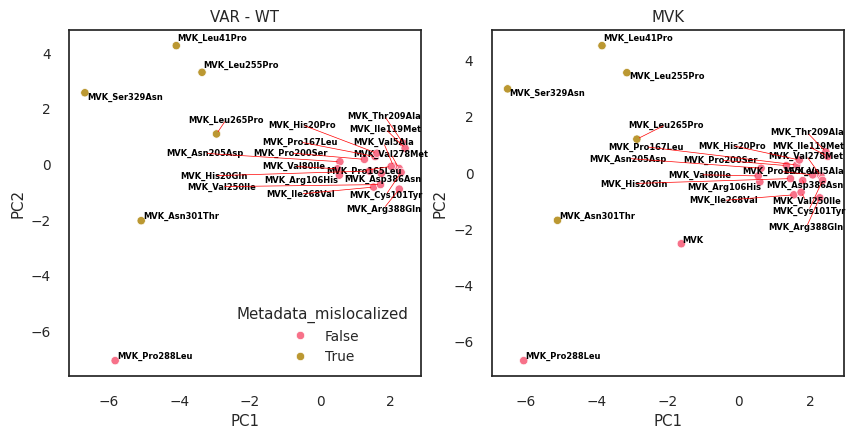

In [53]:
for gene in hits_gene_w_loc_df["Metadata_gene_allele"]:
    gene_df = ref_var_allele_int_featselect_prof_df.filter(
        pl.col("Metadata_gene_allele").str.contains(gene)
    ).with_columns(
        pl.when(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["gene_allele"]))
        .then(True)
        .otherwise(False)
        .alias("Metadata_mislocalized")
    )
    if gene == "MVK":
        gene_row = gene_df.filter(~pl.col("Metadata_gene_allele").str.contains("_"))
        var_rows = gene_df.filter(pl.col("Metadata_gene_allele").str.contains("_"))
        var_rows = var_rows.with_columns(
            [pl.col(c) - gene_row[c] for c in var_rows.columns if "Metadata_" not in c]
        )

        pca = PCA(n_components=2, random_state=42)
        X_pca = pca.fit_transform(var_rows.select([c for c in var_rows.columns if "Metadata_" not in c]).to_numpy())
        X_pca_orig = pca.fit_transform(gene_df.select([c for c in gene_df.columns if "Metadata_" not in c]).to_numpy())
    
        print(X_pca_orig.shape, X_pca.shape)
        umap_df = pd.DataFrame(X_pca_orig, columns=["PC1", "PC2"])
        # umap_df["Metadata_main_loc"] = gene_df["Metadata_main_loc"]
        umap_df["Metadata_gene_allele"] = gene_df["Metadata_gene_allele"]
        umap_df["Metadata_mislocalized"] = gene_df["Metadata_mislocalized"]
        
        pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
        # pca_df["Metadata_main_loc"] = var_rows["Metadata_main_loc"]
        pca_df["Metadata_gene_allele"] = var_rows["Metadata_gene_allele"]
        pca_df["Metadata_mislocalized"] = var_rows["Metadata_mislocalized"]
        
        fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
        sns.scatterplot(data=pca_df, x="PC1", y="PC2", #hue="Metadata_main_loc", palette=custom_palette, 
                        ax=axes[0], hue="Metadata_mislocalized", #hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique()), 
                        # alpha=.2,
                        # color="tomato", 
                        legend=True)
        
        sns.scatterplot(data=umap_df, x="PC1", y="PC2", #hue="Metadata_main_loc", palette=custom_palette,  
                        ax=axes[1],
                        hue="Metadata_mislocalized", #hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique())
                        color="tomato", 
                        # style="",
                        legend=False)
        texts = []
        for i, label in enumerate(pca_df["Metadata_gene_allele"].to_list()):
            texts.append(axes[0].text(pca_df.iloc[i, 0], pca_df.iloc[i, 1], label, 
                            fontsize=6, fontweight='bold', color='black'))
        adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=axes[0]) ## 
    
        texts = []
        for i, label in enumerate(umap_df["Metadata_gene_allele"].to_list()):
            texts.append(axes[1].text(umap_df.iloc[i, 0], umap_df.iloc[i, 1], label, 
                            fontsize=6, fontweight='bold', color='black'))
        adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=axes[1]) ## 
        axes[0].set_title("VAR - WT")
        axes[1].set_title(gene)
        break

In [42]:
## normalize the features
ref_var_allele_int_prof_df = inverse_normal_transform(ref_var_allele_all_prof_df)

## remove corr features
ref_var_allele_int_featselect_prof_df = remove_corr_feats(ref_var_allele_int_prof_df, corr_thres=0.9)

In [114]:
ref_var_allele_proc_prof_df = ref_var_allele_proc_prof_df.join(
    hits_gene_loc_df.select("Metadata_gene_allele","Main location"),
    on="Metadata_gene_allele",
    how="left"
).with_columns(
    pl.when(pl.col("Metadata_gene_allele").str.contains("_"))
    .then(pl.lit("VAR"))
    .otherwise(pl.lit("REF"))
    .alias("Metadata_allele_type"),
    pl.col("Main location").fill_null("Unknown")
).rename(
    {"Main location": "Metadata_main_loc"}
)

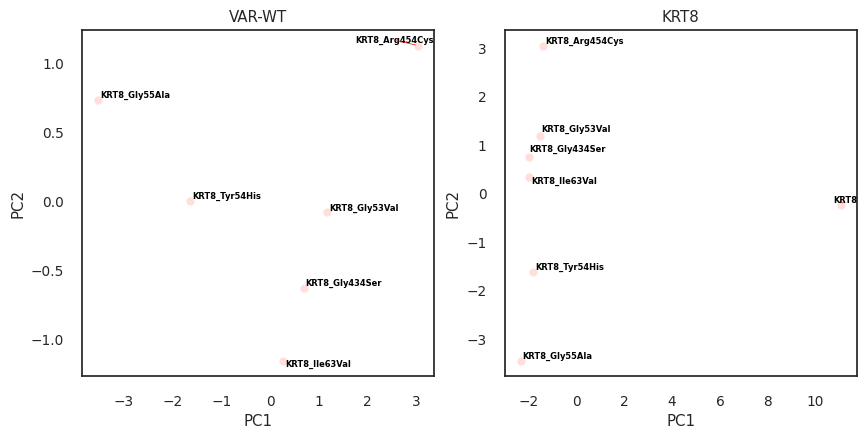

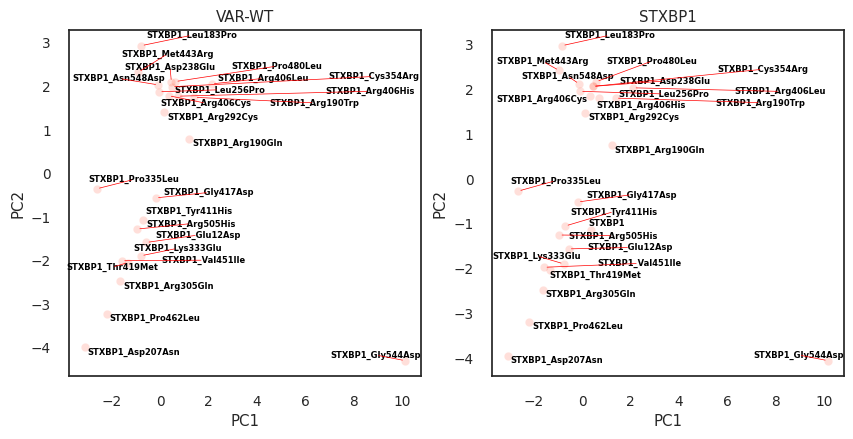

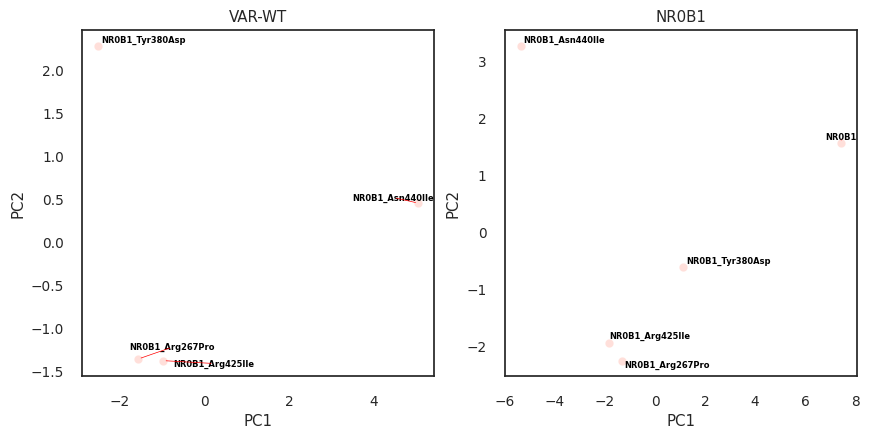

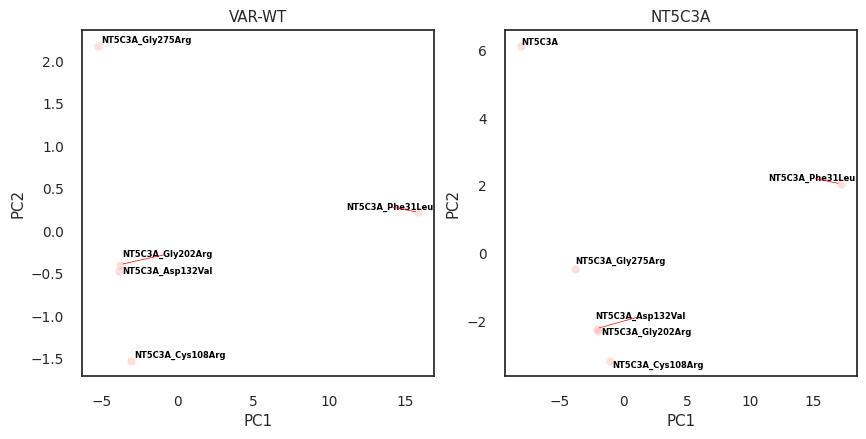

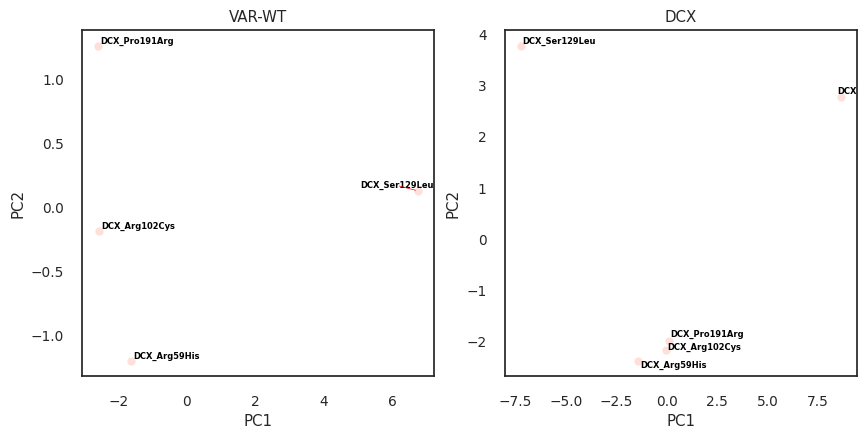

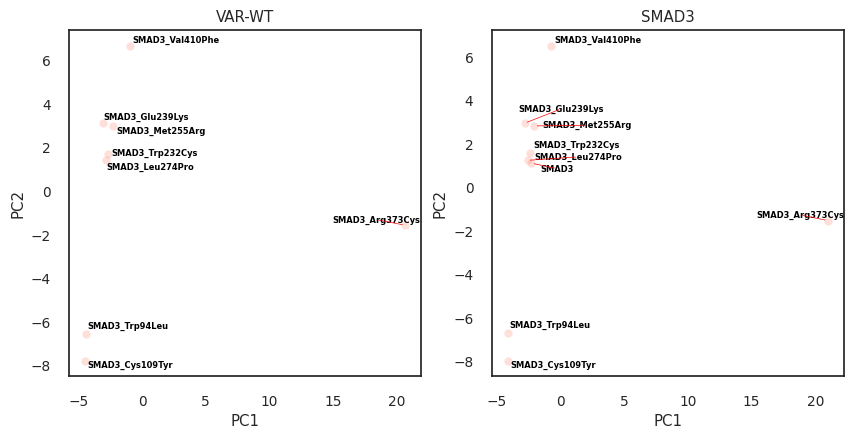

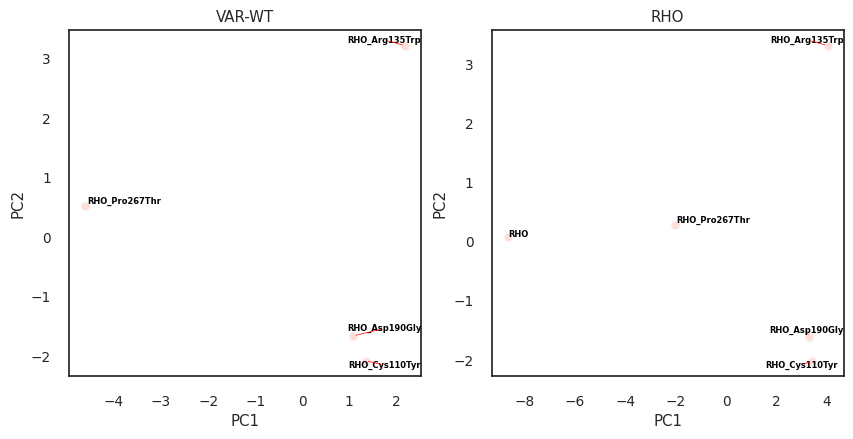

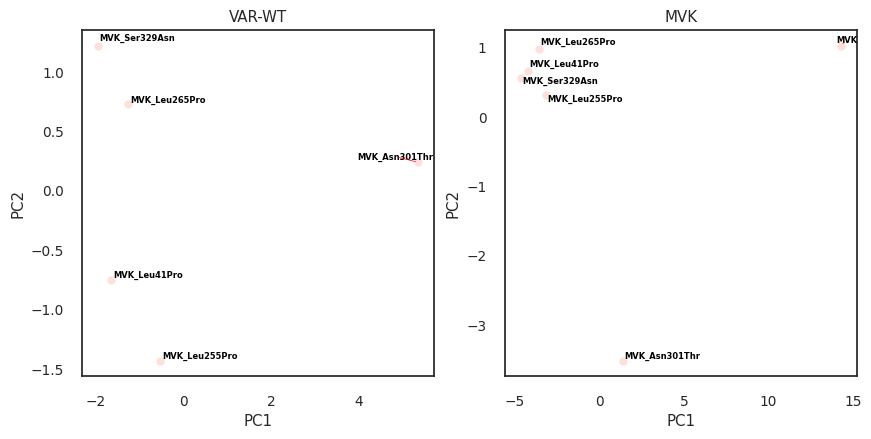

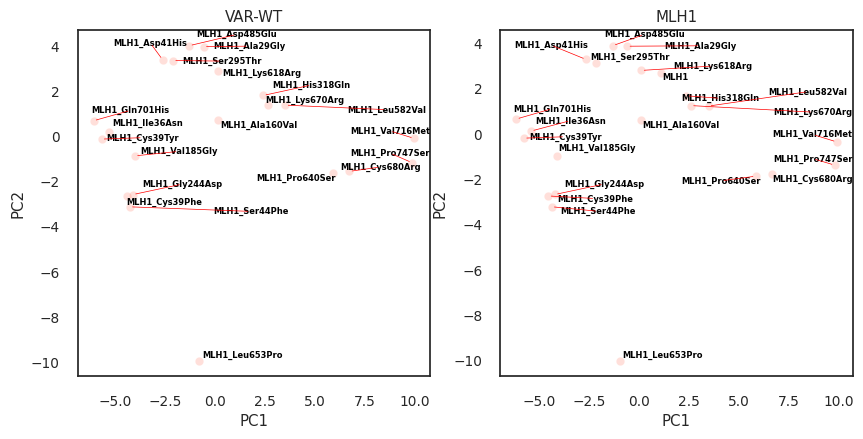

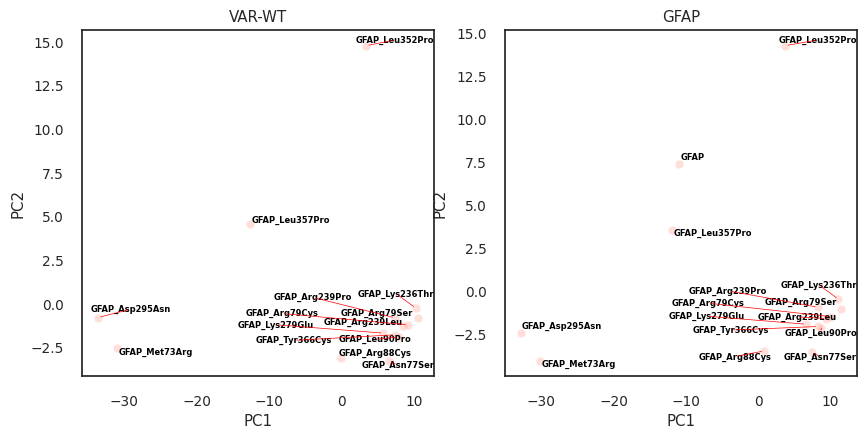

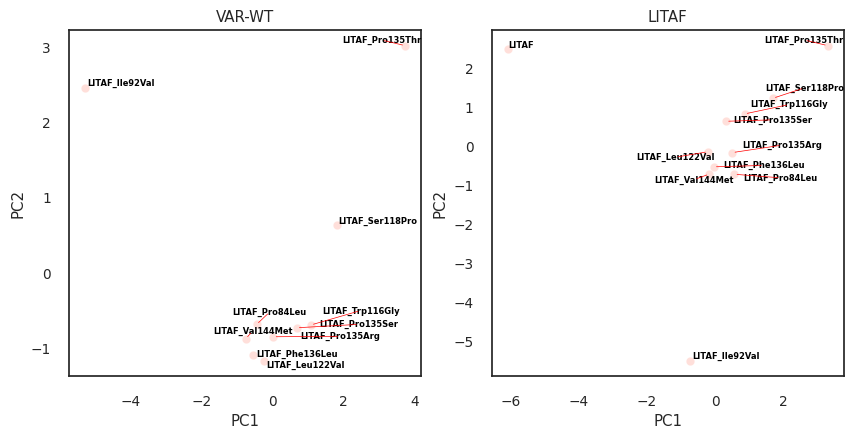

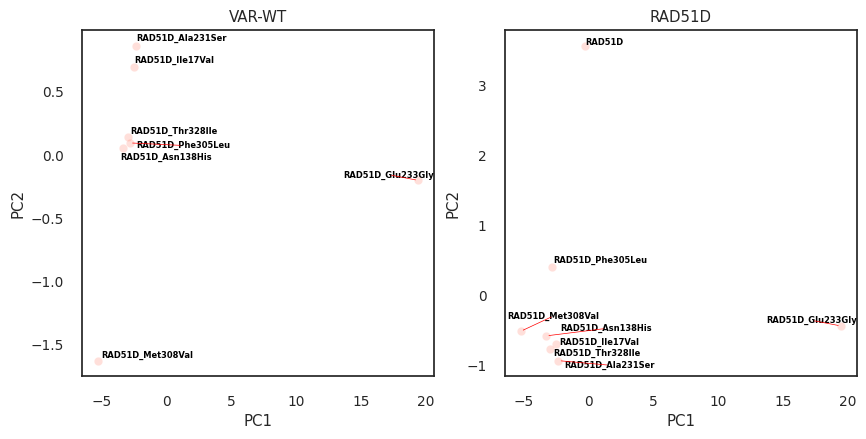

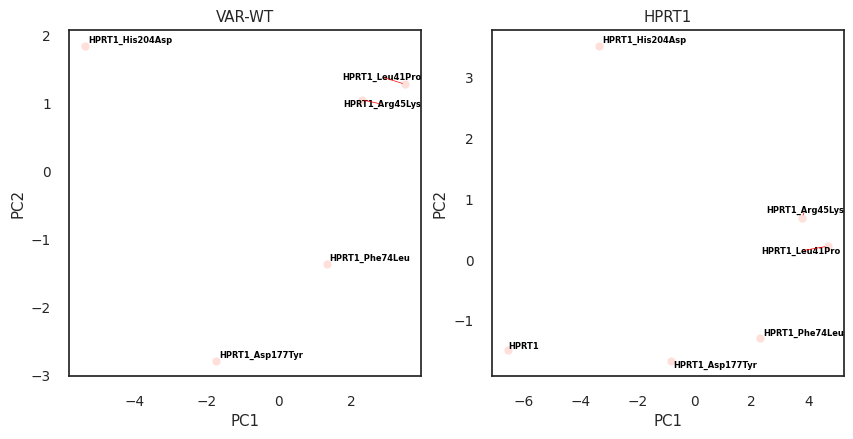

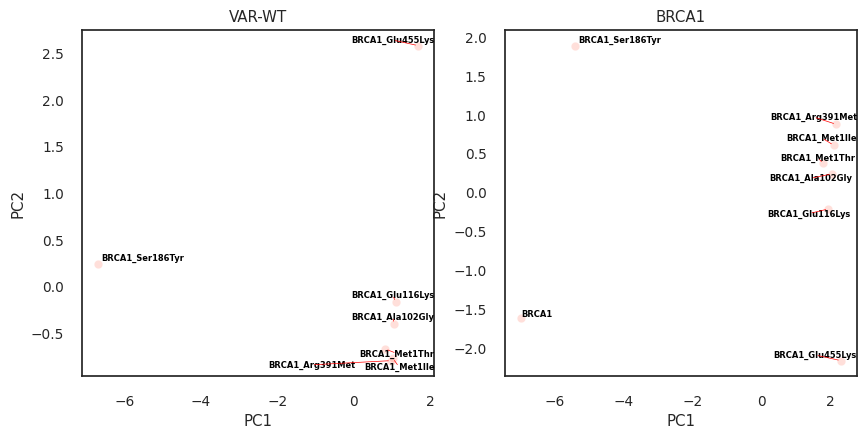

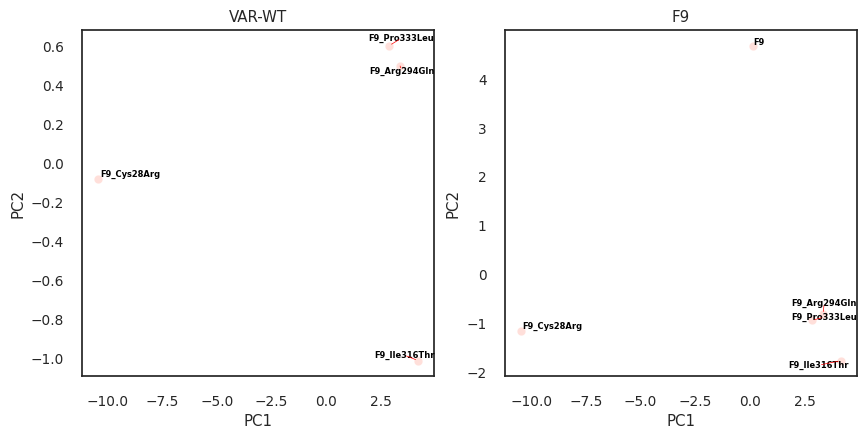

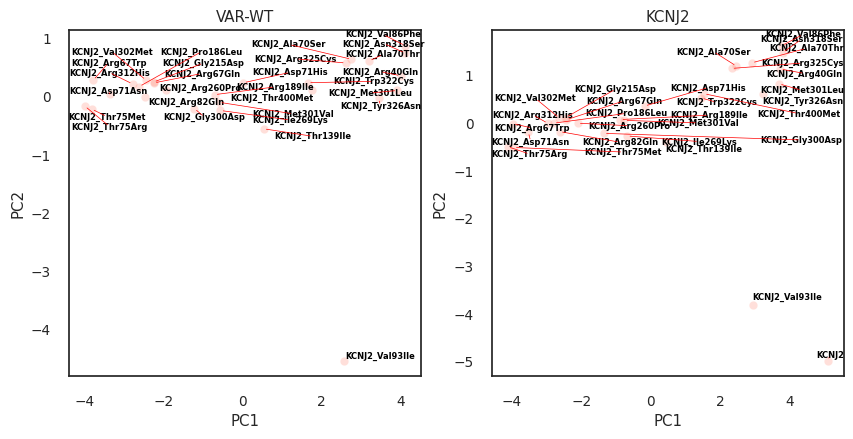

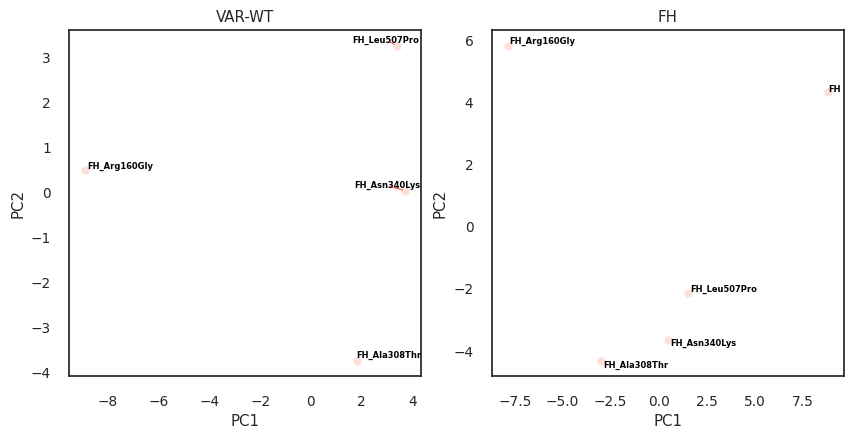

In [127]:
gene_list = ref_var_allele_proc_prof_df.filter(~pl.col("Metadata_gene_allele").str.contains("_"))["Metadata_gene_allele"]
for gene in gene_list:
    gene_df = ref_var_allele_proc_prof_df.filter(pl.col("Metadata_gene_allele").str.contains(gene))
    if gene_df.shape[0] >= 5:
        gene_row = gene_df.filter(~pl.col("Metadata_gene_allele").str.contains("_"))
        var_rows = gene_df.filter(pl.col("Metadata_gene_allele").str.contains("_"))
        var_rows = var_rows.with_columns(
            [pl.col(c) - gene_row[c] for c in var_rows.columns if "Metadata_" not in c]
        )
        # var_rows = pl.concat([
        #     var_rows, gene_row
        # ], how="vertical")
        # display(var_rows)
        # umap_reducer = umap.UMAP(n_components=2, random_state=42, 
        #                        metric='jaccard', n_neighbors=15, min_dist=0.1)
        # X_umap = umap_reducer.fit_transform(var_rows.select([c for c in var_rows.columns if "Metadata_" not in c]).to_numpy())
        
        pca = PCA(n_components=2, random_state=42)
        X_pca = pca.fit_transform(var_rows.select([c for c in var_rows.columns if "Metadata_" not in c]).to_numpy())
        X_pca_orig = pca.fit_transform(gene_df.select([c for c in gene_df.columns if "Metadata_" not in c]).to_numpy())

        umap_df = pd.DataFrame(X_pca_orig, columns=["PC1", "PC2"])
        umap_df["Metadata_main_loc"] = gene_df["Metadata_main_loc"]
        umap_df["Metadata_gene_allele"] = gene_df["Metadata_gene_allele"]
        
        pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
        pca_df["Metadata_main_loc"] = var_rows["Metadata_main_loc"]
        pca_df["Metadata_gene_allele"] = var_rows["Metadata_gene_allele"]
        
        fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
        sns.scatterplot(data=pca_df, x="PC1", y="PC2", #hue="Metadata_main_loc", palette=custom_palette, 
                        ax=axes[0], #style="Metadata_allele_type", hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique()), 
                        color="tomato", alpha=.2,
                        legend=False)
        sns.scatterplot(data=umap_df, x="PC1", y="PC2", #hue="Metadata_main_loc", palette=custom_palette,  
                        ax=axes[1],
                        # style="Metadata_allele_type", hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique())
                        color="tomato", alpha=.2,
                        legend=False)
        texts = []
        for i, label in enumerate(pca_df["Metadata_gene_allele"].to_list()):
            texts.append(axes[0].text(pca_df.iloc[i, 0], pca_df.iloc[i, 1], label, 
                            fontsize=6, fontweight='bold', color='black'))
        adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=axes[0]) ## 

        texts = []
        for i, label in enumerate(umap_df["Metadata_gene_allele"].to_list()):
            texts.append(axes[1].text(umap_df.iloc[i, 0], umap_df.iloc[i, 1], label, 
                            fontsize=6, fontweight='bold', color='black'))
        adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=axes[1]) ## 
        axes[1].set_title(gene)
        axes[0].set_title("VAR-WT")

In [56]:
custom_palette_ = sns.color_palette("colorblind", 10) + \
                 sns.color_palette("Set2", 8) + \
                 sns.color_palette("Dark2", 8) + \
                 sns.color_palette("Pastel1", 9)

# Create palette dictionary with "Unknown" specifically set to grey
unique_locations = sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].unique())
custom_palette = {}

for i, location in enumerate(unique_locations):
    if location == "Unknown":
        custom_palette[location] = '#808080'  # Grey color
    else:
        # Use colors from custom palette, skipping grey colors for other categories
        non_grey_colors = [c for c in custom_palette_ if c not in ['#7f7f7f', '#d9d9d9', '#808080']]
        custom_palette[location] = non_grey_colors[i % len(non_grey_colors)]

Computing UMAP embedding...


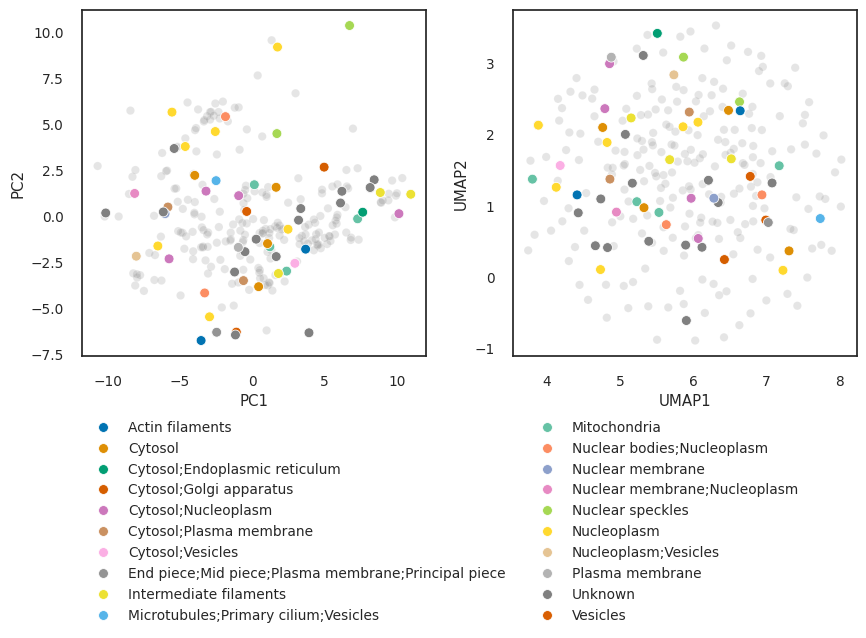

In [65]:
# UMAP - excellent for binary/sparse data
print("Computing UMAP embedding...")
umap_reducer = umap.UMAP(n_components=2, random_state=42, 
                       metric='jaccard', n_neighbors=15, min_dist=0.1)
X_umap = umap_reducer.fit_transform(ref_var_allele_proc_prof_df.select(
    [c for c in ref_var_allele_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(ref_var_allele_proc_prof_df.select(
    [c for c in ref_var_allele_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

umap_df = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_main_loc"] = ref_var_allele_proc_prof_df["Metadata_main_loc"]
umap_df["Metadata_gene_allele"] = ref_var_allele_proc_prof_df["Metadata_gene_allele"]
umap_df["Metadata_allele_type"] = ref_var_allele_proc_prof_df["Metadata_allele_type"]

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Metadata_main_loc"] = ref_var_allele_proc_prof_df["Metadata_main_loc"]
pca_df["Metadata_gene_allele"] = ref_var_allele_proc_prof_df["Metadata_gene_allele"]
pca_df["Metadata_allele_type"] = ref_var_allele_proc_prof_df["Metadata_allele_type"]

fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
sns.scatterplot(data=pca_df[pca_df["Metadata_allele_type"]=="VAR"], x="PC1", y="PC2", hue="Metadata_main_loc", palette=custom_palette, 
                ax=axes[0], #style="Metadata_allele_type", hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique()), 
                color="lightgrey", alpha=.2,
                legend=False)
sns.scatterplot(data=umap_df[umap_df["Metadata_allele_type"]=="VAR"], x="UMAP1", y="UMAP2", hue="Metadata_main_loc", palette=custom_palette,  
                ax=axes[1],
                # style="Metadata_allele_type", hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique())
                color="lightgrey", alpha=.2,
                legend=False)

sns.scatterplot(data=pca_df[pca_df["Metadata_allele_type"]!="VAR"], x="PC1", y="PC2", hue="Metadata_main_loc", palette=custom_palette, 
                ax=axes[0], marker="o", s=50,
                #style="Metadata_allele_type", 
                hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique()), 
                legend=False)
sns.scatterplot(data=umap_df[umap_df["Metadata_allele_type"]!="VAR"], x="UMAP1", y="UMAP2", hue="Metadata_main_loc", palette=custom_palette,  
                ax=axes[1], marker="o", s=50,
                # style="Metadata_allele_type",
                hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique()))
axes[1].legend(bbox_to_anchor=(-0.2, -0.15), ncol=2, loc="upper center")
plt.subplots_adjust(wspace=.25)

In [104]:
feat_df_select = feat_df.filter(
    pl.col("cp_feature").is_in([c for c in ref_var_allele_int_featselect_prof_df.columns if FEAT in c])
).fill_null(0)
feat_df_select_hits = feat_df_select.select(pl.col(["cp_feature"]+imaging_summary_clinvar_hits["gene_allele"].to_list()))

# feat_df_select_hits = feat_df_select_hits.filter(
#     pl.mean_horizontal([c for c in feat_df_select_hits.columns if c != "cp_feature"]) >= 5e-3
# )
feat_df_select_hits

cp_feature,SMARCB1_Pro48Leu,MVK_Leu265Pro,KRT8_Arg454Cys,DES_Asn342Asp,LITAF_Pro84Leu,SMAD3_Cys109Tyr,MLH1_Lys670Arg,KCNJ2_Asp71His,GFAP_Lys236Thr,MLH1_Ala29Gly,KCNJ2_Met301Leu,GFAP_Arg79Ser,MLH1_Pro640Ser,KCNJ2_Val93Ile,HPRT1_Arg45Lys,GFAP_Arg239Leu,KCNJ2_Thr75Arg,SFTPC_Leu188Gln,GFAP_Asn77Ser,FBP1_Phe194Ser,FXN_Trp173Gly,GFAP_Arg88Cys,KCNJ2_Gly300Asp,KCNJ2_Asp71Asn,SFTPA2_Gly231Val,STXBP1_Arg406Leu,STXBP1_Thr419Met,KCNJ2_Thr139Ile,STXBP1_Gly417Asp,LITAF_Trp116Gly,STXBP1_Met443Arg,STXBP1_Val451Ile,MLH1_Gln701His,NR0B1_Arg267Pro,STXBP1_Leu256Pro,AGXT_Gly116Arg,…,BRCA1_Met1Ile,RET_Arg330Gln,ZC4H2_Arg18Lys,SDHD_His102Leu,RAD51D_Thr328Ile,LMNA_Arg377Leu,SOS2_Val869Ile,FH_Arg160Gly,FH_Leu507Pro,RHO_Arg135Trp,RHO_Pro267Thr,F9_Pro333Leu,ZC4H2_Leu66His,RAD51D_Ile17Val,BRCA1_Arg391Met,RAF1_Gly361Ala,BRCA1_Ser186Tyr,FH_Asn340Lys,CTCF_Arg567Trp,KRAS_Phe156Leu,RAD51D_Phe305Leu,F9_Arg294Gln,BRCA1_Glu116Lys,FH_Ala308Thr,BRCA1_Met1Thr,RAD51D_Ala231Ser,BRCA1_Glu455Lys,F9_Cys28Arg,F9_Ile316Thr,RHO_Asp190Gly,BRIP1_Thr266Lys,RAD51D_Glu233Gly,RAD51D_Asn138His,RHO_Cys110Tyr,SHOC2_Ser2Gly,BRCA1_Ala102Gly,RAD51D_Met308Val
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Cells_Correlation_RWC_Mito_GFP""",0.004104,0.015118,0.007607,0.012526,0.006805,0.01013,0.0,0.006794,0.010473,0.0,0.00755,0.010529,0.0,0.005254,0.006274,0.012499,0.082718,0.146456,0.008443,0.016932,0.004775,0.007945,0.075306,0.005831,0.019478,0.0,0.0,0.063405,0.0,0.007383,0.0,0.0,0.0,0.006766,0.0,0.016917,…,0.039128,0.02098,0.011272,0.005133,0.007975,0.002032,0.027679,0.002574,0.011368,0.007759,0.008842,0.013569,0.008592,0.009245,0.033195,0.01475,0.035461,0.007365,0.004115,0.004367,0.010614,0.009754,0.014104,0.008235,0.031653,0.008179,0.00621,0.014336,0.011355,0.002575,0.004272,0.010562,0.009355,0.003498,0.015597,0.027198,0.007289
"""Nuclei_Correlation_K_GFP_AGP""",0.010761,0.0053,0.009562,0.016377,0.00385,0.007634,0.018528,0.004142,0.007018,0.020791,0.005301,0.007143,0.015652,0.007521,0.003655,0.006945,0.008675,0.00774,0.005666,0.099258,0.01704,0.00577,0.011034,0.024213,0.008191,0.011428,0.013347,0.010426,0.010728,0.006068,0.008178,0.011431,0.009651,0.003874,0.010224,0.023517,…,0.00586,0.012385,0.025654,0.006441,0.00763,0.002597,0.02714,0.003212,0.002357,0.008693,0.012794,0.004267,0.005891,0.005369,0.006156,0.010196,0.012367,0.009129,0.004078,0.007197,0.011068,0.008906,0.008648,0.006321,0.006144,0.005533,0.004236,0.009507,0.004964,0.014041,0.00999,0.004642,0.008274,0.006814,0.009003,0.004924,0.009266
"""Cytoplasm_Intensity_MaxIntensi…",0.003882,0.035819,0.011329,0.009624,0.121668,0.02223,0.0,0.004825,0.007795,0.0,0.00528,0.009608,0.0,0.007854,0.005909,0.015794,0.007326,0.003903,0.009053,0.186776,0.007165,0.007359,0.008203,0.006028,0.01182,0.0,0.0,0.007955,0.0,0.011157,0.0,0.0,0.0,0.043091,0.0,0.020743,…,0.005942,0.004776,0.081115,0.003879,0.056354,0.004205,0.065638,0.009368,0.037984,0.016376,0.023724,0.004176,0.017931,0.041862,0.006258,0.048582,0.004288,0.096666,0.004351,0.00786,0.036992,0.009422,0.04839,0.061352,0.006676,0.052535,0.017207,0.082453,0.007127,0.008143,0.004583,0.018769,0.060725,0.006159,0.028845,0.027416,0.078933
"""Cells_RadialDistribution_MeanF…",0.008969,0.019083,0.005332,0.005668,0.004224,0.017721,0.007796,0.009876,0.007076,0.008806,0.007105,0.006685,0.008084,0.004135,0.007144,0.008215,0.004879,0.00413,0.008674,0.012934,0.004045,0.006435,0.00415,0.004454,0.004657,0.005622,0.035268,0.003517,0.040252,0.003187,0.003915,0.028238,0.004334,0.005484,0.008543,0.008494,…,0.005985,0.004914,0.004589,0.007826,0.00824,0.007724,0.002826,0.012565,0.00684,0.011762,0.008835,0.004942,0.005795,0.005157,0.009492,0.004765,0.004504,0.004061,0.005435,0.003085,0.007727,0.002976,0.005348,0.00414,0.006676,0.005748,0.003155,0.005835,0.00499,0.

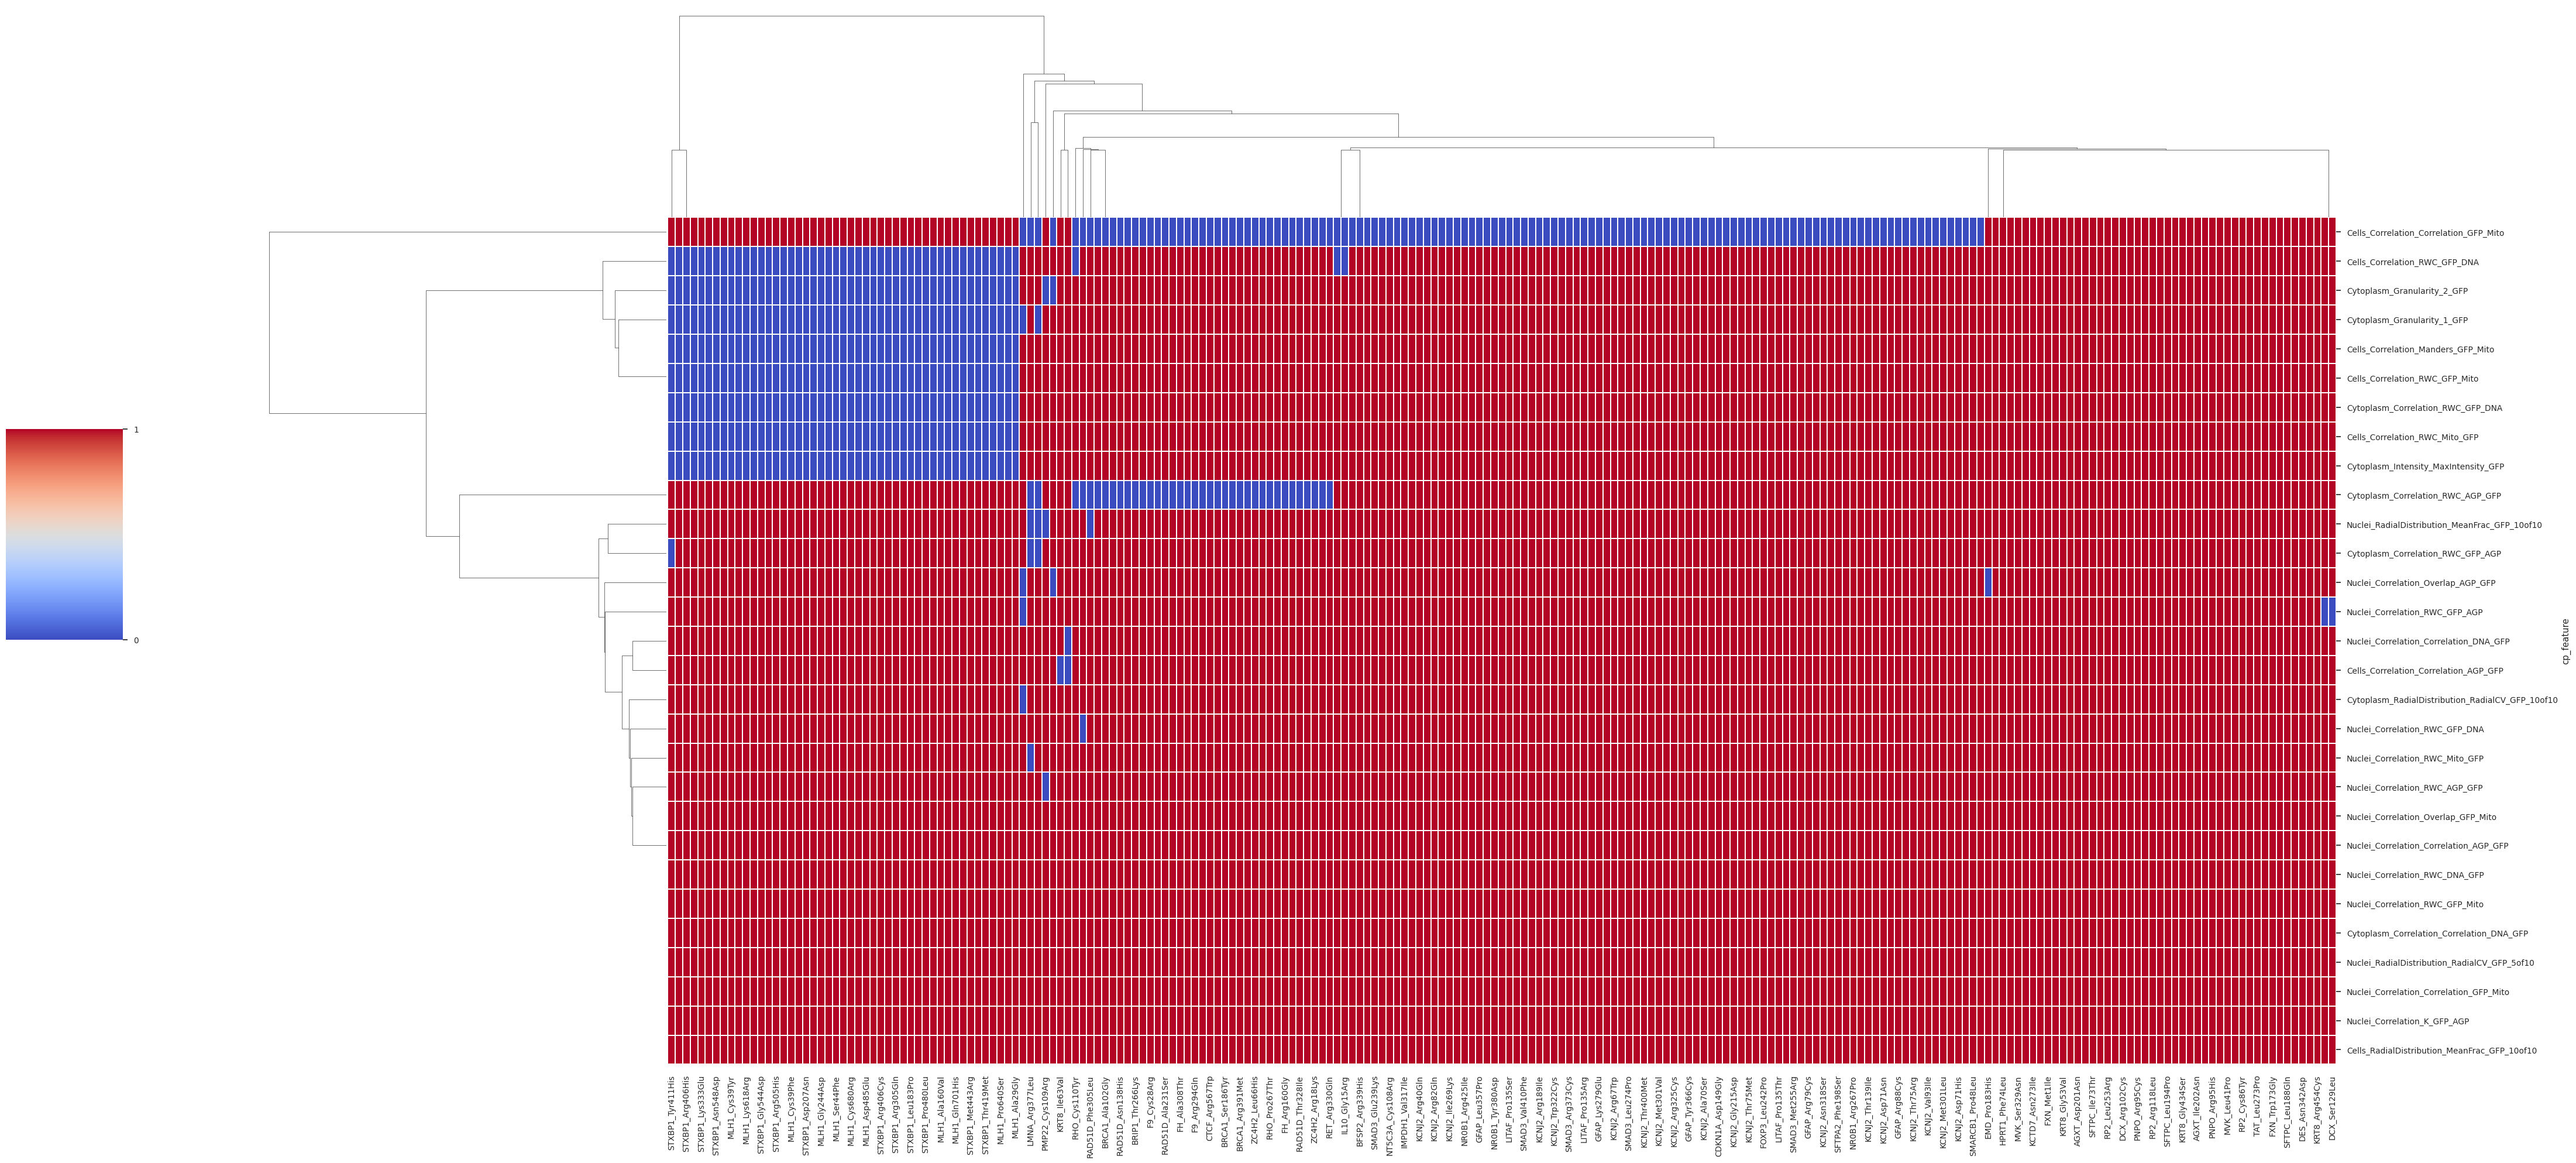

In [80]:
sns.clustermap(
    data=feat_df_select_hits.with_columns(
        pl.col([c for c in feat_df_select_hits.columns if c != "cp_feature"]).map_elements(lambda x: 1 if x > 0 else 0)
    ).to_pandas().set_index("cp_feature"),
    figsize=(40, 20),
    cmap="coolwarm",
    # square=True,
    # ax=ax,
    linewidths=0.2,         # <-- width of the cell borders
    linecolor='white',       # <-- color of the borders
    col_cluster=True,
    cbar_pos=(-0.1, 0.45, 0.05, 0.18),
    cbar_kws={
        "ticks": [0, 1],        # ← only show 0 and 1
        "format": "%d",         # integer formatting
    }
)

In [105]:
misloc_var_diff_wt = pl.DataFrame()
for allele in tqdm(imaging_summary_clinvar_hits["gene_allele"]):
    gene_row = ref_var_allele_int_featselect_prof_df.filter(pl.col("Metadata_gene_allele")==allele.split("_")[0])
    var_rows = ref_var_allele_int_featselect_prof_df.filter(pl.col("Metadata_gene_allele")==allele)
    var_rows = var_rows.with_columns(
        [pl.col(c) - gene_row[c] for c in feat_df_select_hits["cp_feature"]]
    )
    # print(var_rows)
    misloc_var_diff_wt = pl.concat([misloc_var_diff_wt, 
                                    var_rows.select(["Metadata_gene_allele"]+feat_df_select_hits["cp_feature"].to_list())])
# misloc_var_diff_wt.write_csv("../../3_outputs/mislocalized_variant_cp_featselect_diff_wrt_ref.csv")

100%|██████████| 223/223 [00:04<00:00, 46.76it/s]


In [88]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score
from umap import UMAP
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from tqdm import tqdm

custom_palette_ = sns.color_palette("colorblind", 10) + \
                  sns.color_palette("Set2", 8) + \
                  sns.color_palette("Dark2", 8) + \
                  sns.color_palette("Pastel1", 9) + \
                  sns.color_palette("husl", 10)

# ------------------------------------------------------------------
# Load the CSV
# ------------------------------------------------------------------
df = pd.read_csv("../../3_outputs/mislocalized_variant_cp_featselect_diff_wrt_ref.csv", index_col=0)
X  = df.values                 # rows = variants, cols = features
variant_names = df.index
feat_names = df.columns
Xz = StandardScaler().fit_transform(X)

# 2. helper: cluster with *exactly* >= min_size members
# ----------------------------------------------------------------------------
def ward_no_singletons(k, data, min_size=2):
    """Return labels for k clusters, guaranteeing no singletons."""
    while True:
        labels = AgglomerativeClustering(
            n_clusters=k, linkage='average', 
            affinity='cosine').fit_predict(data)
        sizes = np.bincount(labels)
        if np.all(sizes >= min_size):
            return labels
        k -= 1               # reduce k until condition met
        if k < 2:            # safety net
            raise ValueError("Cannot reach k≥2 without singletons.")

max_k = 50
rng = np.random.RandomState(42)
n_boot = 100
consensus = np.zeros((max_k-1, n_boot))   # k vs bootstrap ARI


for b in tqdm(range(n_boot)):
    idx = rng.choice(len(Xz), size=int(0.8*len(Xz)), replace=False)
    ref = ward_no_singletons(2, Xz[idx])      # reference for b=0
    for ki, k in enumerate(range(2, max_k+1), 0):
        labels = ward_no_singletons(k, Xz[idx])
        consensus[ki, b] = adjusted_rand_score(ref, labels)


mean_stab = consensus.mean(axis=1)
opt_k = np.argmax(mean_stab) + 2        # k starts at 2
print("Optimal k (max consensus stability) =", opt_k)

# ----------------------------------------------------------------------------
# 4. final clustering on full data
# ----------------------------------------------------------------------------
final_labels = ward_no_singletons(opt_k, Xz)
cluster_df = pd.Series(final_labels, index=variant_names, name='cluster')

100%|██████████| 100/100 [01:08<00:00,  1.46it/s]

Optimal k (max consensus stability) = 2


In [129]:
clusterer = AgglomerativeClustering(n_clusters=k_star, linkage='average', affinity='cosine')
labels = clusterer.fit_predict(X_scaled)

# Build a DataFrame for downstream plotting
cluster_df = pd.DataFrame({'variant': variant_names, 'cluster': labels})

pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
umap_2d = UMAP(n_components=2, random_state=42, n_jobs=1).fit_transform(X_scaled)

pca_df = pd.DataFrame(pca, columns=["PC1", "PC2"])
pca_df["Cluster"] = labels
pca_df["gene_allele"] = variant_names

umap_df = pd.DataFrame(umap_2d, columns=["UMAP1", "UMAP2"])
umap_df["Cluster"] = labels
umap_df["gene_allele"] = variant_names

pca_df = pl.DataFrame(pca_df).join(
    imaging_summary_clinvar_hits.select(["gene_allele", "clinvar_clnsig_clean"]),
    on="gene_allele"
).to_pandas()
umap_df = pl.DataFrame(umap_df).join(
    imaging_summary_clinvar_hits.select(["gene_allele", "clinvar_clnsig_clean"]),
    on="gene_allele"
).to_pandas()

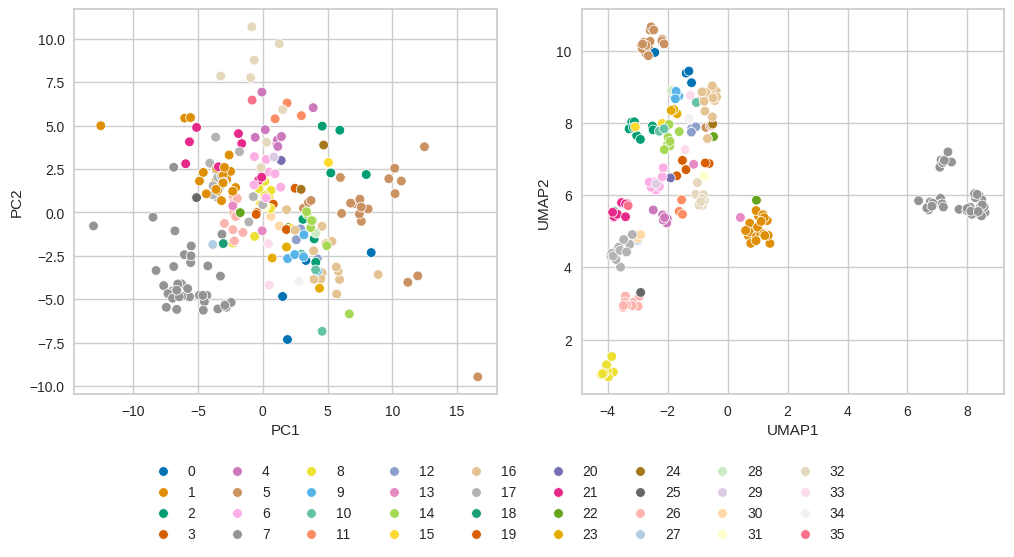

In [82]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    ax=ax[0],
    legend=False,
    palette=custom_palette_
)
sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="Cluster",
    ax=ax[1],
    legend=True,
    palette=custom_palette_
)
ax[1].legend(bbox_to_anchor=(-0.2, -0.15), ncol=9, loc="upper center")
plt.show()

In [97]:
from scipy.cluster.hierarchy import optimal_leaf_ordering

# Compute linkage for pretty ordering
link = linkage(X_scaled, method='average', metric="cosine")
# 2. apply optimal leaf ordering
link_olo = optimal_leaf_ordering(link, X_scaled)

X_scaled_df = pd.DataFrame(X_scaled, index=variant_names, columns=feat_names).T

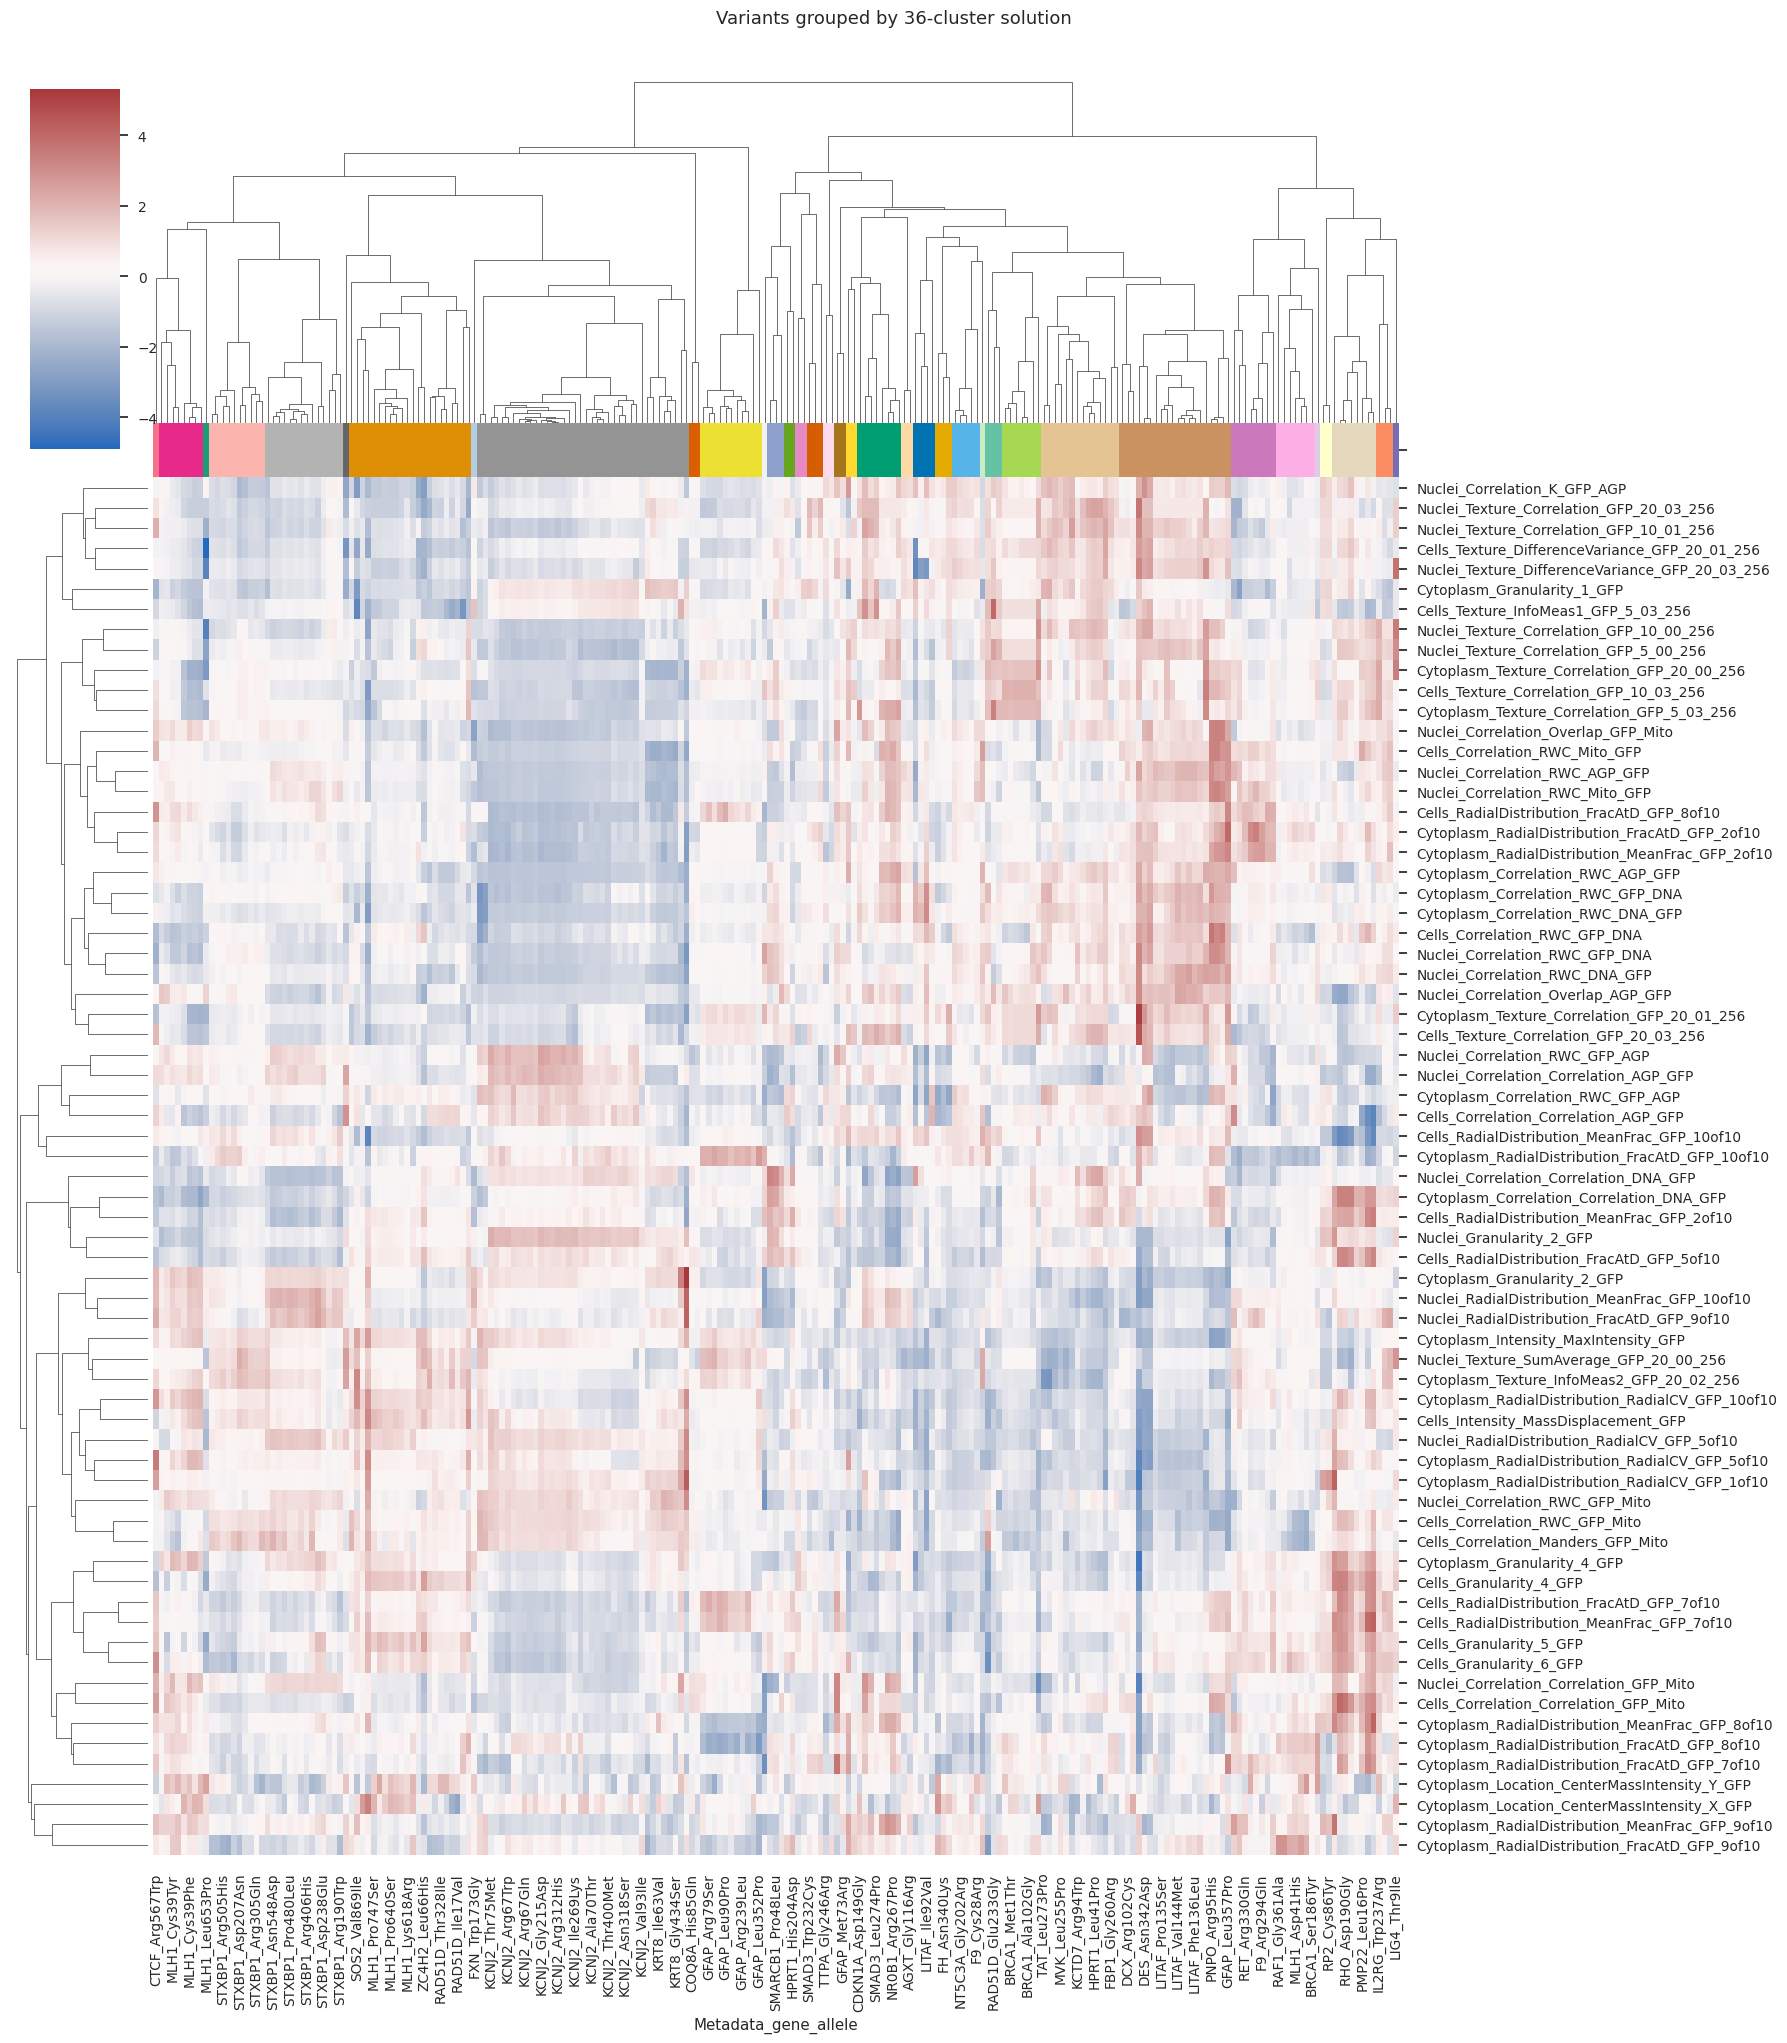

In [98]:
sns.clustermap(
    X_scaled_df,
    row_cluster=True,
    col_linkage=link_olo,
    z_score=0,
    cmap='vlag',
    col_colors=pd.Series(labels, index=variant_names).map(
        {i: custom_palette_[i] for i in range(k_star)}),
    dendrogram_ratio=(.1, .2),
    figsize=(18, 20),
)
plt.suptitle(f"Variants grouped by {k_star}-cluster solution", y=1.02)
plt.show()

<ipython-input-134-e2361cfb03d1>:13: UserWarning: The palette list has more values (45) than needed (4), which may not be intended.
  sns.scatterplot(
<ipython-input-134-e2361cfb03d1>:43: UserWarning: The palette list has more values (45) than needed (4), which may not be intended.
  sns.scatterplot(


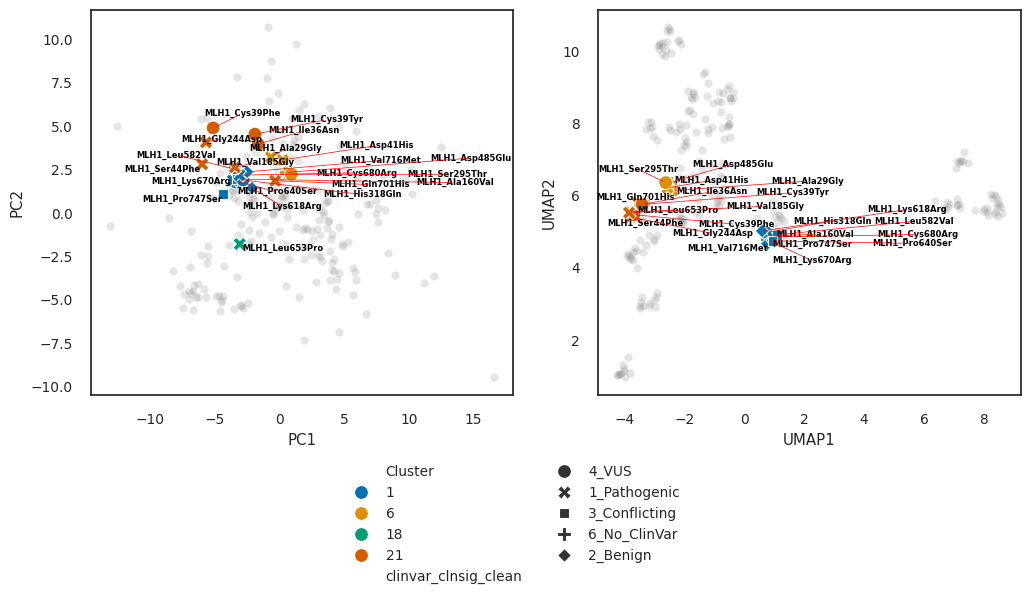

In [134]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    # hue="Cluster",
    color="grey",
    ax=ax[0],
    legend=False,
    alpha=.2,
    # palette=custom_palette_
)
sns.scatterplot(
    data=pca_df[pca_df["gene_allele"].str.contains("MLH1")],
    x="PC1",
    y="PC2",
    hue="Cluster",
    ax=ax[0],
    legend=False,
    palette=custom_palette_,
    style="clinvar_clnsig_clean",
    s=100
)
texts = []
for i, label in enumerate(pca_df[pca_df["gene_allele"].str.contains("MLH1")]["gene_allele"].to_list()):
    texts.append(ax[0].text(pca_df[pca_df["gene_allele"].str.contains("MLH1")].iloc[i, 0], 
                              pca_df[pca_df["gene_allele"].str.contains("MLH1")].iloc[i, 1], 
                              label, 
                    fontsize=6, fontweight='bold', color='black'))
adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[0]) ## 

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    # hue="Cluster",
    color="grey",
    ax=ax[1],
    legend=False,
    alpha=.2,
    # palette=custom_palette_
)
sns.scatterplot(
    data=umap_df[umap_df["gene_allele"].str.contains("MLH1")],
    x="UMAP1",
    y="UMAP2",
    hue="Cluster",
    ax=ax[1],
    legend=True,
    style="clinvar_clnsig_clean",
    palette=custom_palette_,
    s=100
)

texts = []
for i, label in enumerate(umap_df[umap_df["gene_allele"].str.contains("MLH1")]["gene_allele"].to_list()):
    texts.append(ax[1].text(umap_df[umap_df["gene_allele"].str.contains("MLH1")].iloc[i, 0], 
                              umap_df[umap_df["gene_allele"].str.contains("MLH1")].iloc[i, 1], label, 
                    fontsize=6, fontweight='bold', color='black'))
adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[1]) ## 

ax[1].legend(bbox_to_anchor=(-0.2, -0.15), ncol=2, loc="upper center")
plt.show()

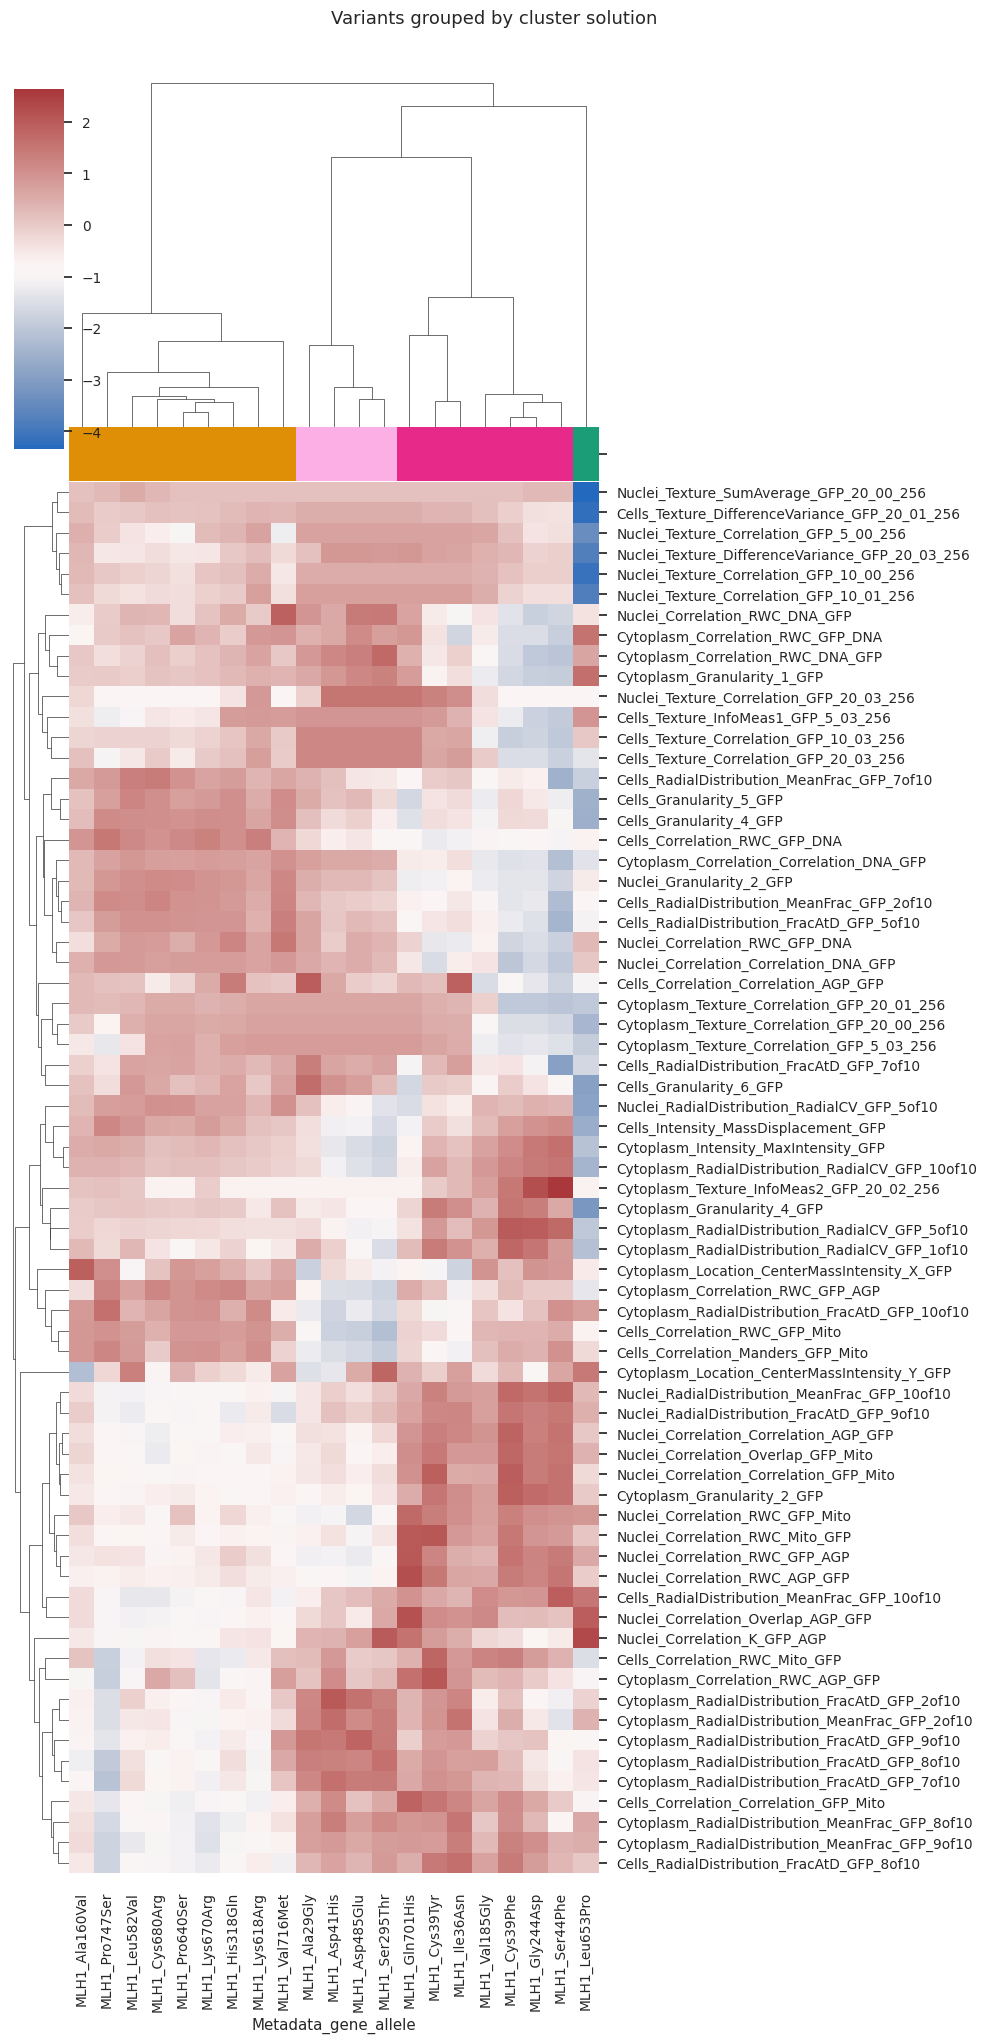

In [121]:
# Compute linkage for pretty ordering
mlh1_var = [idx for idx in X_scaled_df.columns if "MLH1" in idx]

link = linkage(X_scaled_df.loc[:,mlh1_var].T, method='average', metric="cosine")
# 2. apply optimal leaf ordering
link_olo = optimal_leaf_ordering(link, X_scaled_df.loc[:,mlh1_var].T)
labels = umap_df[umap_df["gene_allele"].str.contains("MLH1")]["Cluster"].values
var_labels = umap_df[umap_df["gene_allele"].str.contains("MLH1")]["gene_allele"].values

sns.clustermap(
    X_scaled_df.loc[:,mlh1_var],
    row_cluster=True,
    col_linkage=link_olo,
    z_score=0,
    cmap='vlag',
    col_colors=pd.Series(labels, index=var_labels).map(
        {i: custom_palette_[i] for i in range(k_star)}),
    dendrogram_ratio=(.1, .2),
    figsize=(10, 20),
)
plt.suptitle(f"Variants grouped by cluster solution", y=1.02)
plt.show()

In Cell Painting assays analyzed with CellProfiler, the feature called Cytoplasm_Granularity refers to the texture of the staining pattern within the cytoplasm, specifically measuring how “grainy” or “speckled” the signal is at different spatial scales.

Here’s a breakdown:

__What it Measures:__

* Granularity is a texture feature that captures the size and frequency of bright spots (or granules) in the image at multiple spatial scales.

* It’s based on morphological operations (often using granulometry) to assess how much image content (signal) is removed by a series of opening operations with structuring elements of increasing sizes.

* High granularity indicates numerous small, bright objects in the cytoplasm (e.g., vesicles, organelles).

* Low granularity implies a more uniform or diffuse staining pattern.

__How It Works in CellProfiler:__

* For each cytoplasm region, CellProfiler computes how much of the signal is lost when applying filters that remove structures below certain sizes.

* The result is a series of granularity features, each corresponding to a different scale (e.g., Cytoplasm_Granularity_1, Cytoplasm_Granularity_2, …).

* These scales correspond to different object sizes: smaller numbers = finer textures; larger numbers = coarser granules.

__In Cell Painting:__

* Different dyes highlight organelles like mitochondria, endoplasmic reticulum, Golgi, etc.

* Cytoplasm_Granularity can reflect changes in organelle morphology or distribution due to chemical or genetic perturbations.

* It’s used as a phenotypic descriptor in high-content screening and profiling.